# Lab 3 - Filter banks

Explore the design of filter banks, first designing the bandpass filters and building a filter bank structure that is able to obtain a perfect reconstruction of a sound.

## References:

### Low-pass filter
A low-pass filter is a filter that passes signal components with frequencies lower than a selected cutoff frequency and attenuates signal components with frequencies higher than the cutoff frequency.

### firwin
Algorithm in `scipy.signal` to perform an FIR filter design using the window method. This involves designing an ideal filter in the frequency domain and then applying a window function to smooth the frequency response and limit the number of taps (filter order).

### Bandpass filter
A band-pass filter is a filter that passes frequencies within a certain range and rejects (attenuates) frequencies outside that range. It's the opposite of a band-stop filter.

### Impulse response of a filter
A filter's impulse response function is simply the output of the filter when the input is an impulse of amplitude 1 at time zero.

### Frequency response of a filter
The frequency response of a filter is computed by taking the Fourier Transform of the impulse response and tells us how the filter affects the magnitudes and phases of the frequencies of a signal.

### Filter bank structure
An array of bandpass filters that separates the input signal into multiple components, each one carrying a sub-band of the original signal.

### Perfect reconstruction
Coding/decoding with which we recover the origianl sound identically.

### Critical sampling
In audio coding, critical sampling means that the encoding representation is of the same size than the original signal.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd
from scipy.io.wavfile import read
from scipy.fft import fft
from scipy import signal as signal

In [2]:
# functions used in the whole lab
def read_sound(file):
  """ read a mono wav sound file, assuming is mono, and convert it to a floating point array
    Args:
      file (str): File name
    Returns:
      sound_array (numpy.array): Array of samples as floating point values between -1 and 1
      sampling_rate (int): Sampling rate
  """
  # read sound file
  sampling_rate, x = read(file)
  # convert to floating point values between -1 and 1, assuming x are 16 bit integers
  sound_array = np.float32(x) / 2**15
  return sound_array, sampling_rate

def display_sound(sound_array, sampling_rate=44100):
  """ Display signal sound_array
    Args:
      sound_array (numpy.array): Array of samples
      sampling_rate (int): Sampling rate
  """
  # plot the waveform of the sound
  plt.figure(0, figsize=(10, 4))
  time_indexes = np.arange(0, sound_array.size/sampling_rate, 1.0/sampling_rate)
  plt.plot(time_indexes, sound_array)
  plt.xlabel('time (seconds)')
  plt.ylabel('amplitude')
  plt.show()
  # play the sound
  ipd.display(ipd.Audio(data=sound_array, rate=sampling_rate))

def display_spectrum(sound_array, sampling_rate=44100):
  """ Display magnitude spectrum of signal sound_array
    Args:
      sound_array (numpy.array): Array of samples
      sampling_rate (int): Sampling rate
  """
  # compute the hanning window
  window = signal.get_window('hann', sound_array.size)
  # compute the spectrum of the windowed input signal
  spectrum = fft(window*sound_array)
  # compute the magnitude spectrum in dB
  magnitude_spectrum = 20*np.log10(abs(spectrum[:spectrum.size//2]))

  # plot the magnitude spectrum
  plt.figure(0, figsize=(10, 5))
  frequency_indexes = np.arange(0, sampling_rate/2, sampling_rate/spectrum.size)
  plt.plot(frequency_indexes, magnitude_spectrum)
  plt.xlabel('frequency (Hz)')
  plt.ylabel('amplitude (dB)')
  plt.show()

def display_spectrogram(sound_array, hop_size=256, fft_size=512, sampling_rate=44100):
  """ Display magnitude spectrogram of signal sound_array
    Args:
      sound_array (numpy.array): Array of samples
      hop_size (int): window hop size
      fft_size (int): Spectrogram fft size
      sampling_rate (int): Sampling rate of sound
  """
  # compute the hanning window
  window = signal.get_window('hann', fft_size)
  # initialize the output spectrogram
  magnitude_spectrogram = []
  sample_index = 0
  # iterate over the input sound computing a sequence of spectra
  while sample_index < sound_array.size-fft_size:
    spectrum = fft(window*sound_array[sample_index:sample_index+fft_size])
    magnitude_spectrum = 20*np.log10(abs(spectrum[:spectrum.size//2]))
    magnitude_spectrogram.append(magnitude_spectrum)
    sample_index += hop_size

  # plot the magnitude sspectrogram
  plt.figure(figsize=(10, 5))
  time_indexes = np.arange(0, sample_index/sampling_rate, hop_size/sampling_rate)
  frequency_indexes = np.arange(0, sampling_rate/2, sampling_rate/fft_size)
  plt.pcolormesh(time_indexes, frequency_indexes, np.transpose(magnitude_spectrogram), shading='nearest', cmap='inferno')
  plt.colorbar(format='%+2.0f dB')
  plt.xlabel('time (seconds)')
  plt.ylabel('frequency (Hz)')
  plt.show()

def plot_freq_response(w, h, title):
  "Utility function to plot frequency response functions"
  fig = plt.figure(figsize=(10, 5))
  ax = fig.add_subplot(111)
  ax.plot(w, 20*np.log10(np.abs(h)))
  ax.set_ylim(-80, 5)
  ax.grid(True)
  ax.set_xlabel('Frequency (Hz)')
  ax.set_ylabel('Gain (dB)')
  ax.set_title(title)

def prototype_filter(N, L):
  """ Generate a prototype FIR low-pass filter using a window method.
    Args:
      N (int): length of filter
      L (int): number of subbands
    Returns:
      Coefficients of the resulting FIR filter
  """
  return signal.firwin(N, 1.0 / (2 * L), window='hamming')

def modulate_filter(h, M, k):
    # Modulate the prototype filter
    n = np.arange(len(h))
    modulation = 2 * np.cos(np.pi * (2 * k + 1) * (n - (len(h) - 1) / 2) / (2 * M))
    return h * modulation

def analysis_filter_bank(x, M, N):
    # Analysis Filter Bank using Polyphase Decomposition
    h = prototype_filter(N, M)
    subband_length = len(x) // M
    subbands = np.zeros((M, subband_length))

    for k in range(M):
        hk = modulate_filter(h, M, k)
        filtered_signal = signal.lfilter(hk, 1.0, x)
        # Ensure the subband length matches the expected size
        downsampled_signal = filtered_signal[::M]
        if len(downsampled_signal) > subband_length:
            subbands[k] = downsampled_signal[:subband_length]
        else:
            subbands[k, :len(downsampled_signal)] = downsampled_signal

    return subbands

def synthesis_filter_bank(subbands, M, N):
    # Synthesis Filter Bank using Polyphase Decomposition
    h = prototype_filter(N, M)
    y_reconstructed = np.zeros(M * len(subbands[0]))

    for k in range(M):
        hk = modulate_filter(h, M, k)
        upsampled_signal = np.zeros(len(y_reconstructed))
        upsampled_signal[::M] = subbands[k]  # Upsample by M
        y_reconstructed += signal.lfilter(hk, 1.0, upsampled_signal)

    return y_reconstructed

## Part 1 - Low-pass filtering

Design a low-pass filter using the window method, `firwin` algorithm, and filter a sound with it. Answer the questions given and modify the code to support your answers.

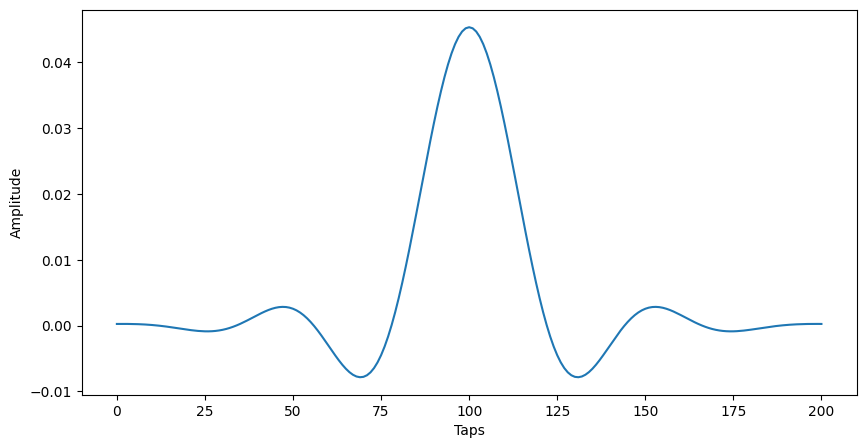

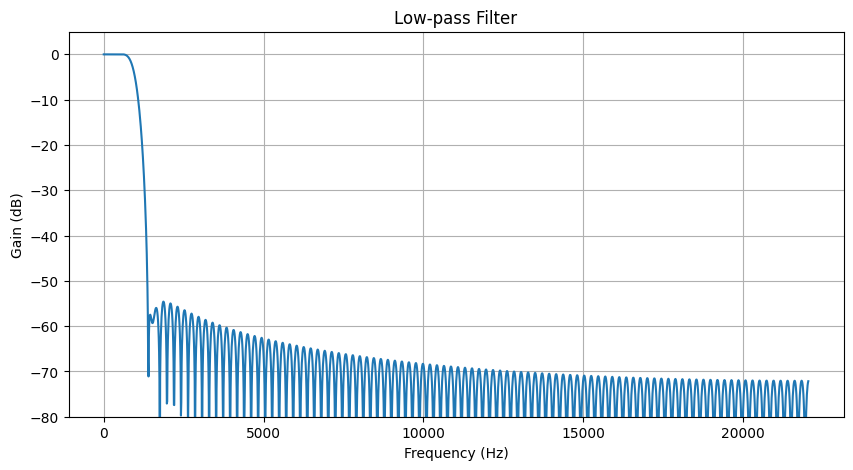

In [3]:
# design a low pass filter
fs = 44100.0
filter_length = 201
cutoff = 1000
h = signal.firwin(filter_length, cutoff, window='hamming', fs=fs)

# plot impulse response of filter
plt.figure(figsize=(10, 5))
plt.plot(h)
plt.xlabel('Taps')
plt.ylabel('Amplitude')
plt.show()

# plot frequency response of filter
w, H = signal.freqz(h, [1], worN=2000, fs=fs)
plot_freq_response(w, H, "Low-pass Filter")
plt.show()

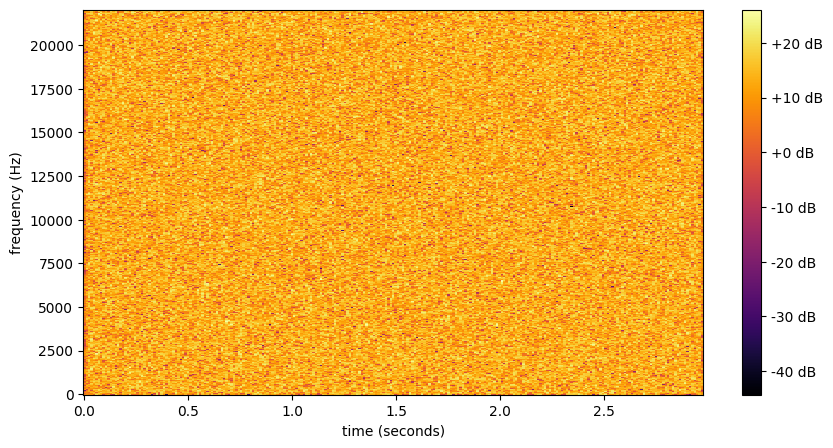

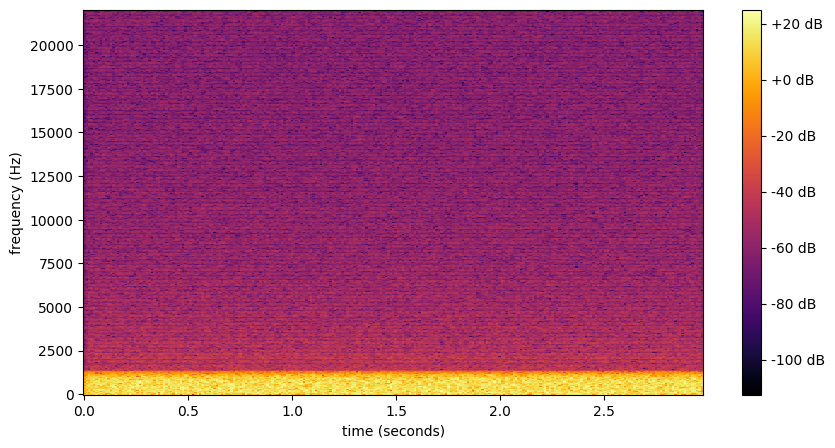

In [4]:
# filter a sound with the lowpass filter
sound_array, sampling_rate = read_sound('../sounds/white-noise.wav')
# apply filter by convolving the sound with the impulse response of filter
filtered_sound = signal.lfilter(h, 1, sound_array)
# display original sound
ipd.display(ipd.Audio(data=sound_array, rate=sampling_rate))
display_spectrogram(sound_array, 512, 1024, sampling_rate)
# display filtered sound
ipd.display(ipd.Audio(data=filtered_sound, rate=sampling_rate))
display_spectrogram(filtered_sound, 512, 1024, sampling_rate)

<font color=red> ***MY MODIFIED CODE*** </font>

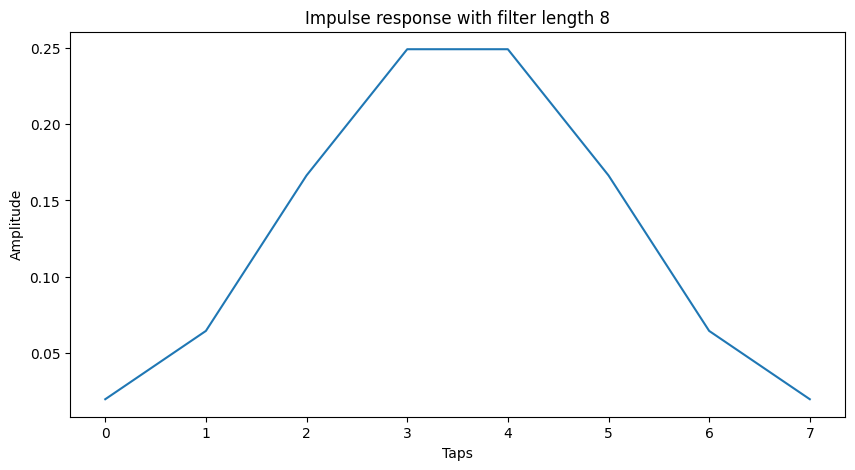

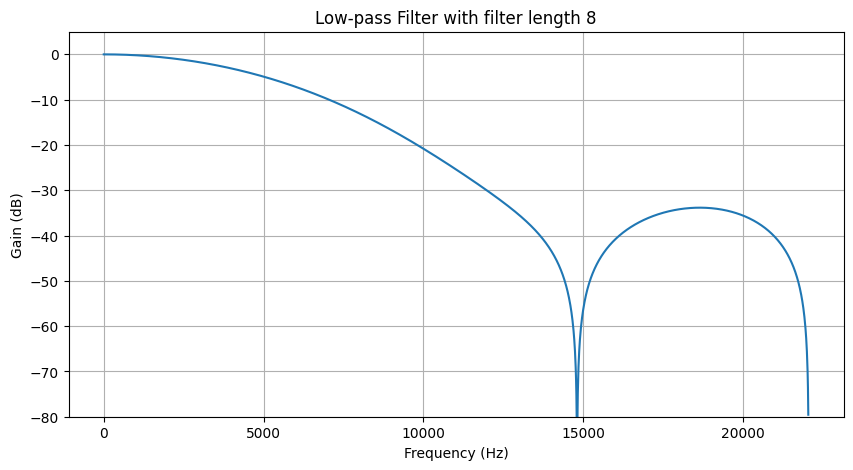

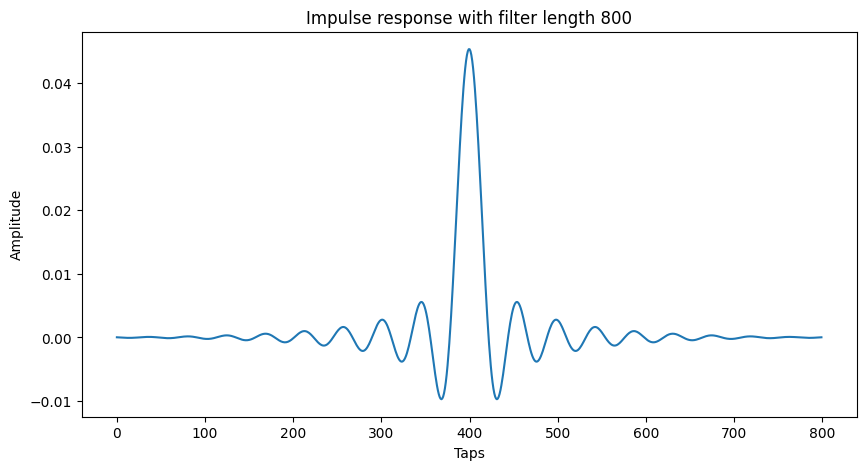

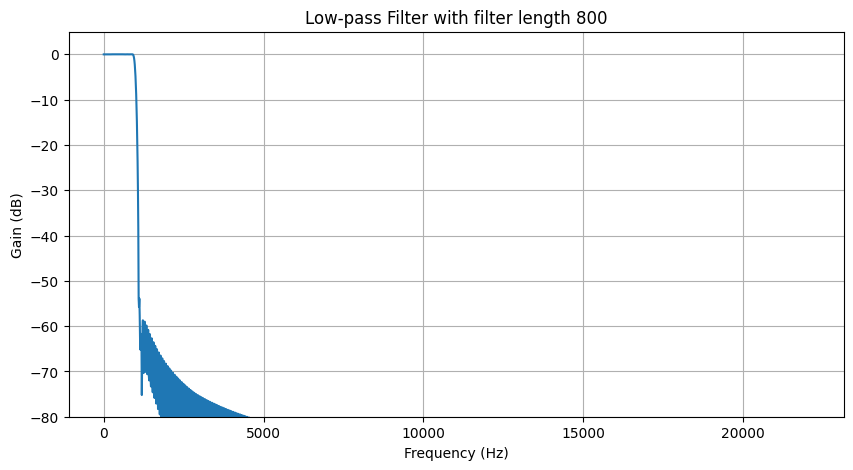

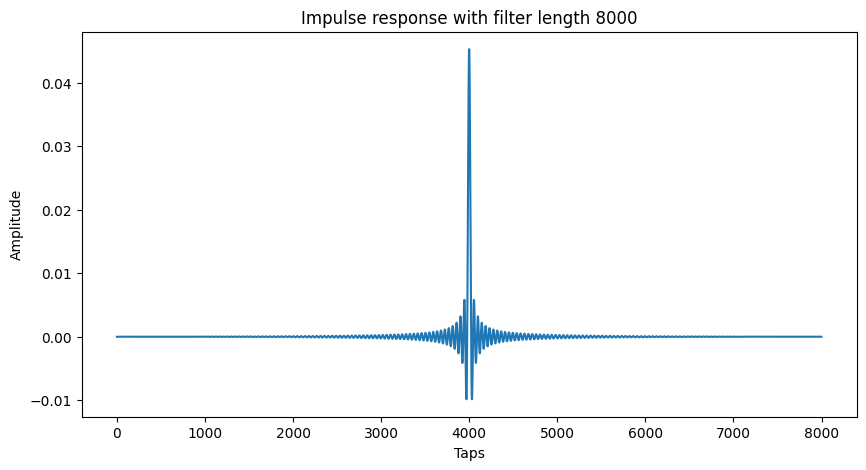

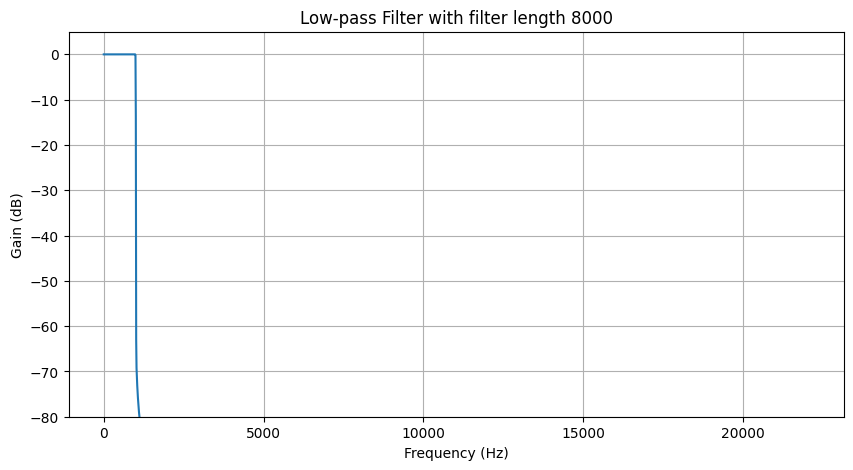

In [5]:
# DESIGNING THE LOW-PASS FILTER AND SHOWING THE IMPULSE AND FREQUENCY RESPONSE

# Step 01: Design
fs = 44100.0
filter_lengths = [8,800,8000]
cutoff = 1000
h_tot = []
for filter_length in filter_lengths:

    h = signal.firwin(filter_length, cutoff, window='hamming', fs=fs)
    h_tot.append(h)

    # Step 02: Showing Impulse Response
    plt.figure(figsize=(10, 5))
    plt.plot(h)
    plt.title(f"Impulse response with filter length {filter_length}")
    plt.xlabel('Taps')
    plt.ylabel('Amplitude')
    plt.show()

    # Step 03: Showing frequency response
    w, H = signal.freqz(h, [1], worN=2000, fs=fs)
    plot_freq_response(w, H, f"Low-pass Filter with filter length {filter_length}")
    plt.show()

 Original White Noise Sound


Spectogram of original White Noise Sound


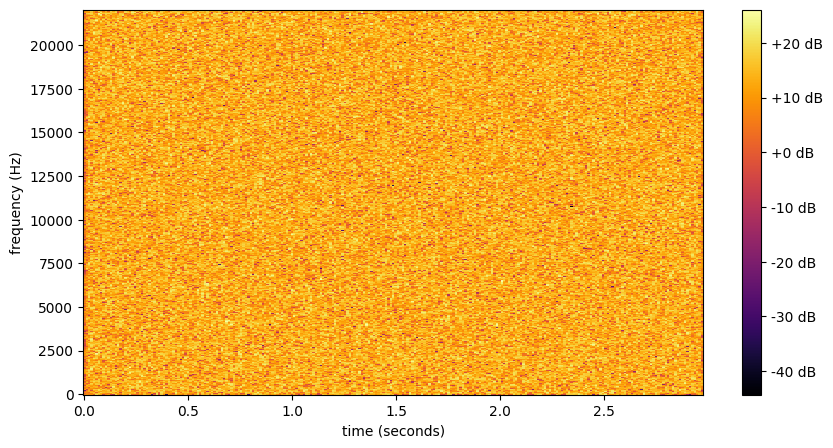

Filtered White Noise sound with LPF length 8


Spectogram of filtered White Noise sound with LPF length 8


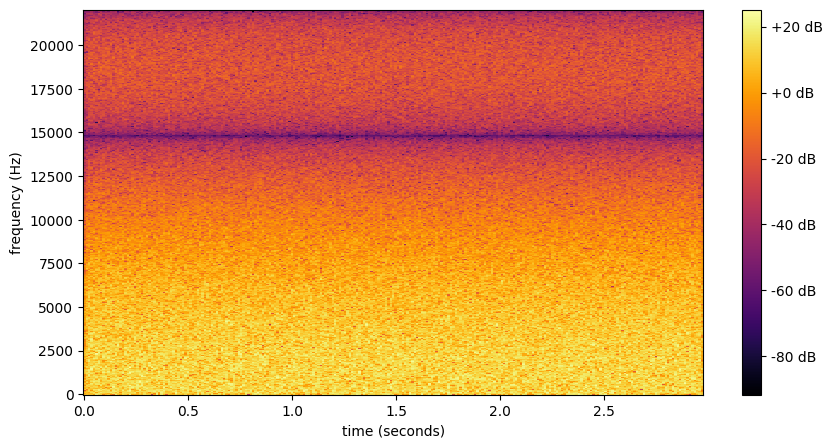

Filtered White Noise sound with LPF length 800


Spectogram of filtered White Noise sound with LPF length 800


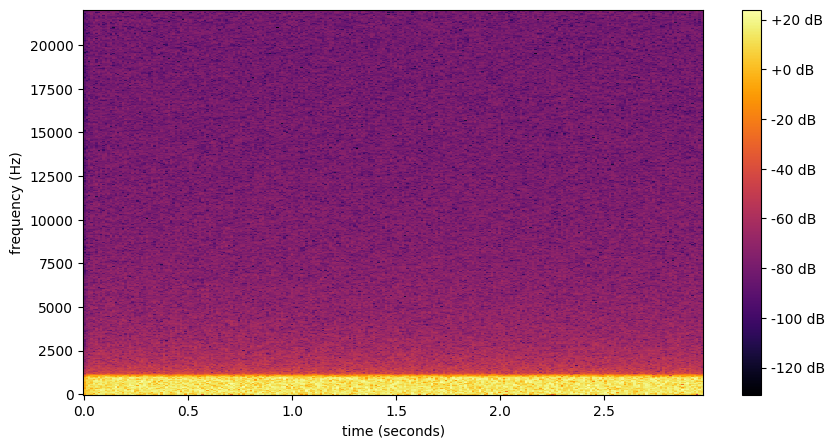

Filtered White Noise sound with LPF length 8000


Spectogram of filtered White Noise sound with LPF length 8000


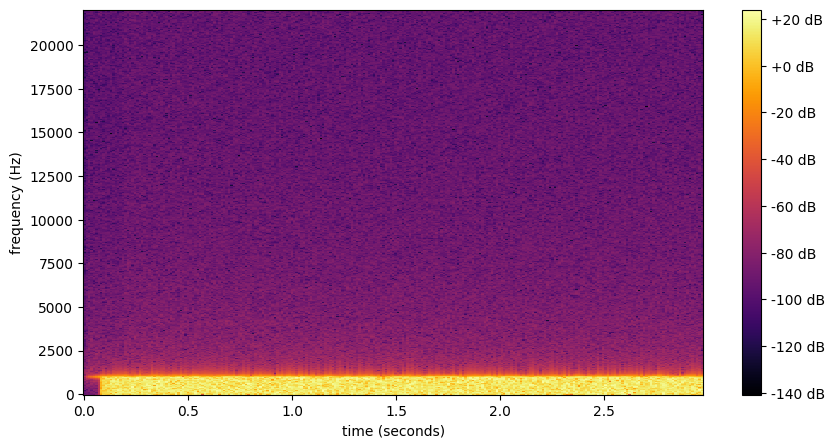

In [6]:
## FILTERING THE WHITE-NOISE SOUND WITH THE PREVIOYS LPFs

# Step 01: Read the sound
sound_array, sampling_rate = read_sound('../sounds/white-noise.wav')

# Step 02: Display the original white-noise sound
print(" Original White Noise Sound")
ipd.display(ipd.Audio(data=sound_array, rate=sampling_rate))
print("Spectogram of original White Noise Sound")
display_spectrogram(sound_array, 512, 1024, sampling_rate)

# Step 03: Apply filter by convolving the sound with the impulse response of filter
for h, filter_length in zip(h_tot, filter_lengths):
    filtered_sound = signal.lfilter(h, 1, sound_array)

    # Step 04: Display the filtered white-noise sound
    print("Filtered White Noise sound with LPF length", filter_length )
    ipd.display(ipd.Audio(data=filtered_sound, rate=sampling_rate))
    print("Spectogram of filtered White Noise sound with LPF length", filter_length)
    display_spectrogram(filtered_sound, 512, 1024, sampling_rate)

**Questions:**

1. Design a lowpass filter with cutoff frequency of 2000Hz, using the `firwin` algorithm with different values for filter-length. Try values of 8, 800, 8000. Show the frequency responses and explain the differences.

    <font color=red> I have modified the original code of the notebook in order to create the 3 filters with the 3 different filter lengths: 8, 800, and 8000. I have plotted both the impulse and the frequency response. 
    
    About the impulse response, I can see that the 3 of them follow the same shape (since it is the same kind of filter), but the greater the filter length, the more detailed the impulse response is. This is seen better between the filter with length 800 and the one with length 8000. The peak with higher amplitude gets narrower and narrower as the filter length increases.
    
    About the frequency response, we can see that the greater the filter length, the more accurate the low pass filter is. 
    We want it to eliminate (or reduce as much as possible) the frequencies above 2000 Hz, meaning that the correct frequency response would be one that is more or less constant from 0 to 2000 Hz on 0 dB, that is, no modification on the amplitude of the original sound in these range of frequencies. And then, on 2000 Hz it decays very sharply until almost -60 to -80 dB amplitude, meaning that it lowers 60 to 80 dBs the amplitude of the original sound in these range of frequencies, making them unperceivable.
    
    - The filter created that gets closer to this "ideal LPF" is the filter with length 8000, since it mantains the amplitude at 0 from 0 to 2000 Hz, and then decreases at almost a straight line until -70 or -80 dBs.
    
    - On the other hand, the worst low pass filter is the one with length 8, since it shows an extremely smooth frequency response. We see how it decays smoothly from 0 to almost 14000 Hz, and then it increases again in amplitude at 15000 Hz until it starts to decrease again around 18 or 19 KHz approximately. Therefore, we do not only have a lot of frequencies mantained that we do not want, but in addition they are not decaying in dBs constantly over time.
    
    However, there the greater the filter length, the more complex and costly it is, and in this case, a low pass filter at 2000 Hz with length 800 is good enough, since the frequencies from 0 to 2000 Hz will be mantained with the same amplitude, and from that point on they will lower in magnitude until -60 dB very sharply, and from 2000 Hz to 5000 Hz they will slowly decrease until -80 dBs.  </font>

2. Filter the sound `white-noise.wav` with the filters designed in question 1. Listen and explain the results, supporting it by showing the spectrograms of the filtered sounds.

    <font color=red> On another cell of the notebook I have modified the original code to apply the 3 filters to the White Noise sound, display the audios, and show the corresponding spectograms.
    
    Let us start with the perceptual analysis. The original sound is just white noise, meaning: a sound with all frequencies and all frequencies at the same magnitude. It is what we can describe as static noise. 
    
    - On the audio with the application of the LPF with length 8 I can slightly perceive that some of the highest frequencies have been decreased, however, it is still contains a lot of the frequencies of the spectrum and they are very perceivable. This sound is still very similar to the static sound of the TV or the radio.
    
    - On the audio with the application of the LPF with length 800, I cannot perceive anymore the highest frequencies. We are left with noise with low frequencies. This audio is more similar to strong wind blowing rather than the static sound of TV or radio.
    
    - On the audio with the application of the LPF with length 8000 I perceive exactly the same as the previous sound. I find no differences at all, even though I know there are. This can be due to the magnitude of the differences. 
    
    To see the actual differences between the sounds, let us analyze the spectograms. We can think of the spectograms as if we inserted the frequency response of the filter above the original spectogram, and the result of these 2 things is the new spectogram of the new sound. So:
    
    - The spectogram of the filtered sound with length 8 is very similar to the original sound. We can see how form frequency 0 to approximately frequency 7500 Hz their magnitude is the same than on the original. This is the point on the frequency response of the filter where the frequencies started to decrease more than 10 dB. We can also see how they keep decaying until reaching -60 dBs at aproximately 14500 Hz, which is exactly -80 dBs less than the original magnitude of the frequency, and exactly the point at which it reduces -80 dB on the frequency response. Then we have a bit of an increase until approximately 19000 Hz, and starts decaying again, but more smoothly. This follows exactly the frequency response of the filter.
    
    - The spectogram of the filtered sound with length 800 is extremely different to the original sound. We can see how the only frequencies mantained in magnitude are the ones between 0 and 2000 Hz, at 2000 Hz exactly they decrease about -60 dBs, and then they decrease more smoothly until 500 Hz, which they arrive to being -80 dBs less than the frequencies of the original sound. This spectogram also follows exactly the frequency response of its filter.
    
    - Lastly, the spectogram of the filtered sound with length 8000 is also extremely different to the original, but very somilar to the previous one. In this case the frequencies mantained are also from 0 to 2000 Hz, but there are two differences. First of all that from 2000 Hz until the end the frequencies have been reduced -80 dB with no smoothness at all, and secondly, that at the beggining of the sound there is a very small fraction of a second (less than 0.1) where the frequencies have also been decreased. However, it is something unperceivable to the ear.

    So having analyzed the 3 new filtered sounds, the previous hypothesis that the filter with length 800 would be good enough for this sound is proven. In addition, it can even be better than the one with length 8000, since it has the error at the beggining. </font>
---

## Part 2 - Bank of bandpass filters

Design a bank of band-pass filters and apply it to a sound. Answer the questions given and modify the code to support your answers.

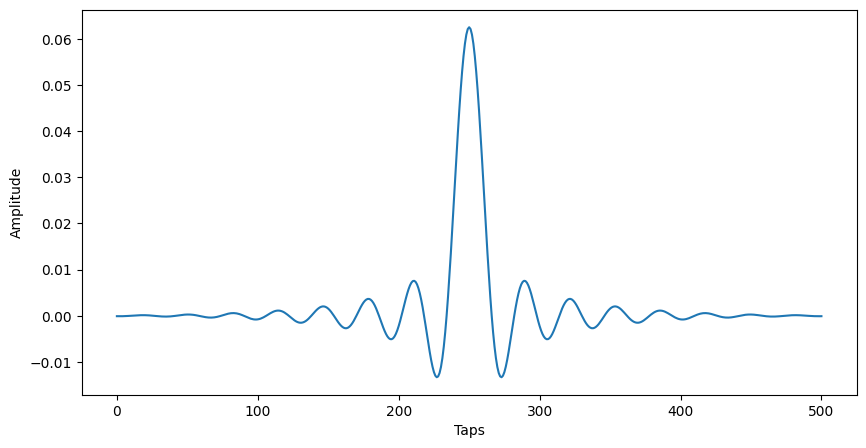

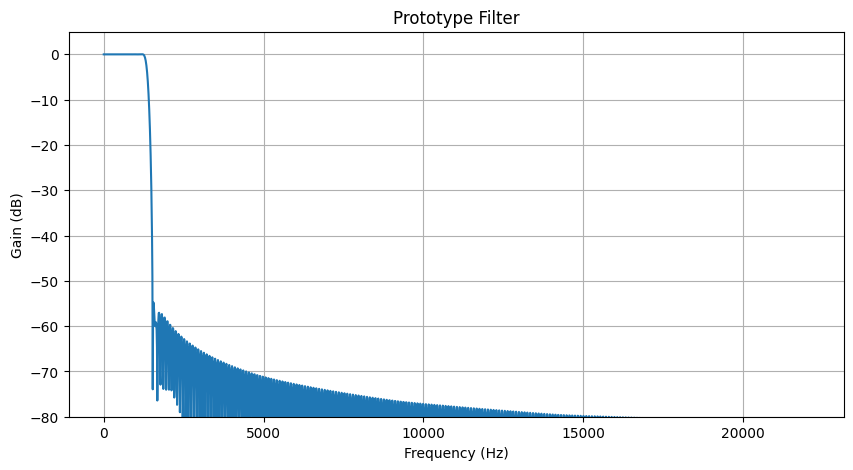

<Figure size 1000x500 with 0 Axes>

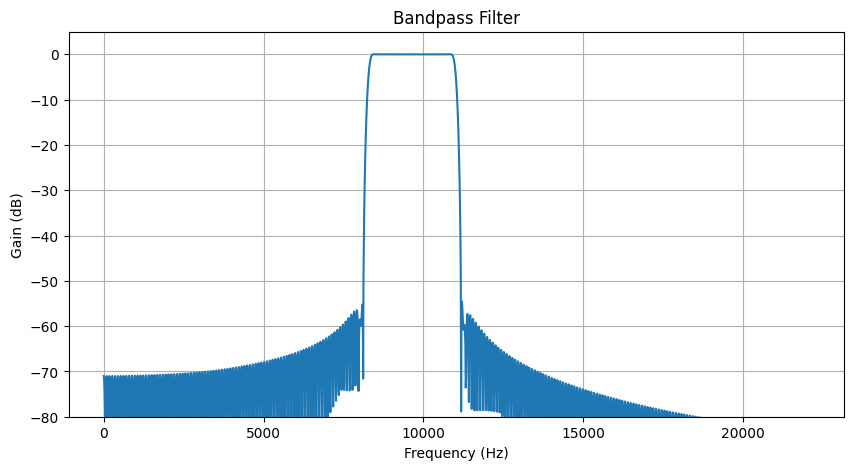

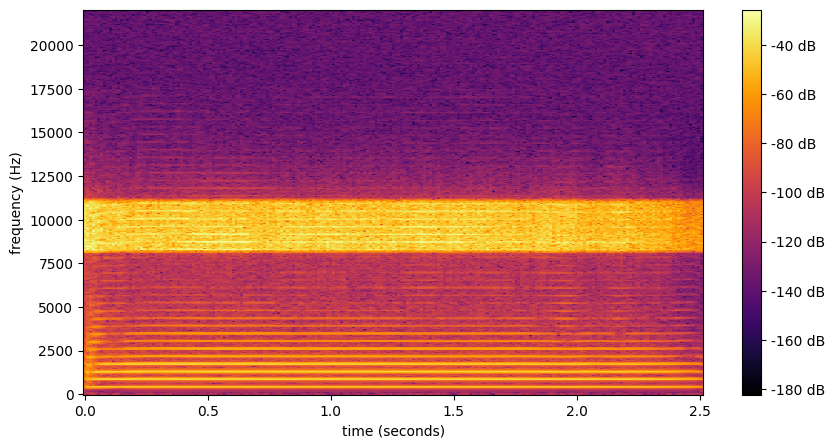

In [7]:
# Parameters for the filter bank
N = 501 # Length of the prototype filter
L = 8   # Number of subbands
fs = 44100  # Sampling rate

# Generate the prototype filter
h = prototype_filter(N, L)

# Plot the prototype filter
plt.figure(figsize=(10, 5))
plt.plot(h)
plt.xlabel('Taps')
plt.ylabel('Amplitude')

w, H = signal.freqz(h, [1], worN=2000, fs=fs)
plot_freq_response(w, H, "Prototype Filter")
plt.show()

# Create a bandpass filter
k = 3  # index of a band pass filter
hk = modulate_filter(h, L, k)

plt.figure(figsize=(10, 5))
w, H = signal.freqz(hk, [1], worN=2000, fs=fs)
plot_freq_response(w, H, "Bandpass Filter")
plt.show()

# filter a sound with the bandpass filter
sound_array, sampling_rate = read_sound('../sounds/487465-trumpet.wav')
# apply filter by convolving the sound with the impulse response of filter
filtered_sound = signal.lfilter(hk, 1, sound_array)
# display filtered sound
ipd.display(ipd.Audio(data=filtered_sound, rate=sampling_rate))
display_spectrogram(filtered_sound, 512, 1024, sampling_rate)


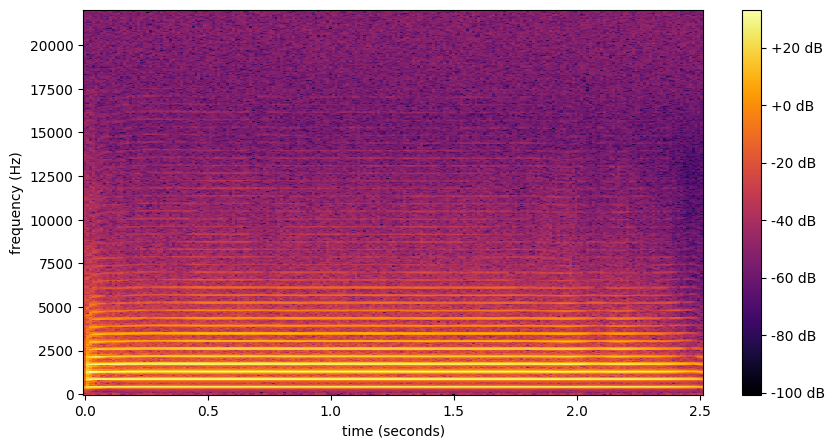

In [8]:
y = np.zeros(len(sound_array))

# apply the whole filter bank to a sound
for k in range(L):
  # Modulate prototype filter
  hk = modulate_filter(h, L, k)
  # Filter the signal
  filtered_sound = signal.lfilter(hk, 1, sound_array)
  y += filtered_sound

# display filtered sound
ipd.display(ipd.Audio(data=y, rate=sampling_rate))
display_spectrogram(y, 512, 1024, sampling_rate)

<font color=red> ***MY MODIFIED CODE*** </font>

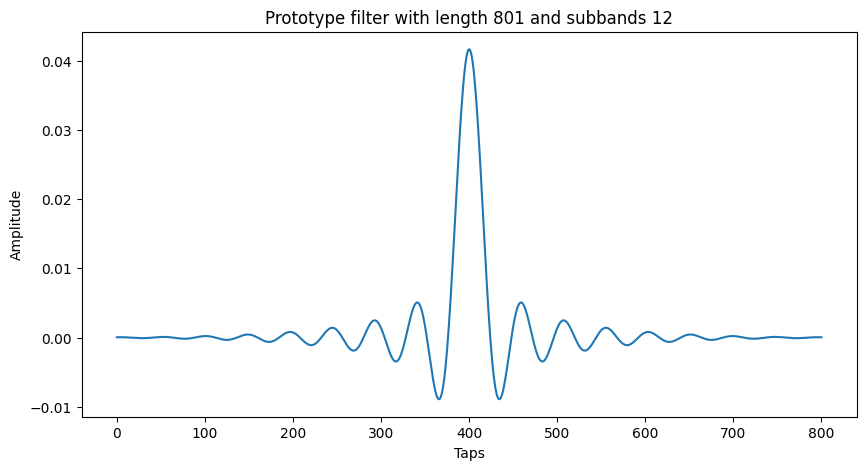

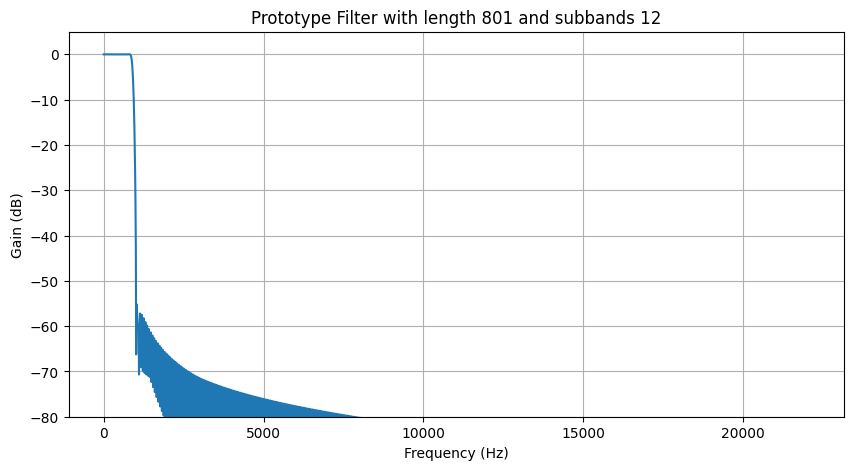

<Figure size 1000x500 with 0 Axes>

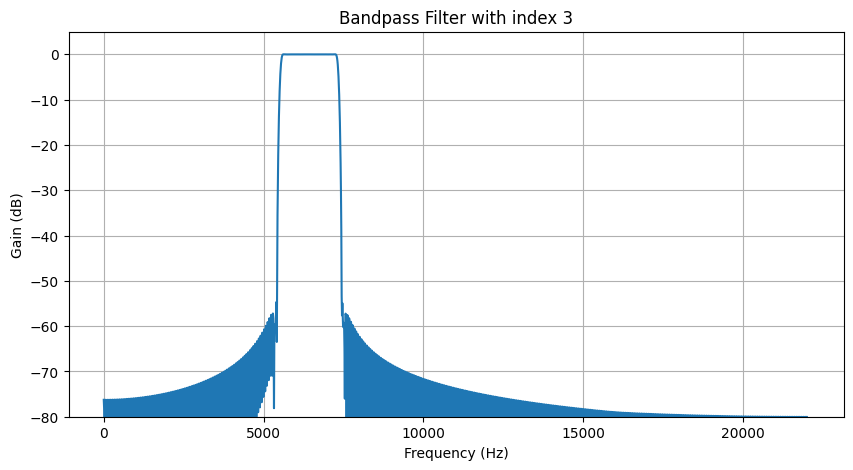

In [9]:
## IMPLEMENTING A LPF AND CONVERTING IT TO A BPF

# Step 01: Defining the Parameters for the filter bank
N = 801 
L = 12   
fs = 44100  

# Step 02: Generating  the prototype filter
h = prototype_filter(N, L)

# Step 03: Ploting the prototype filter
plt.figure(figsize=(10, 5))
plt.plot(h)
plt.xlabel('Taps')
plt.ylabel('Amplitude')
plt.title(f"Prototype filter with length {N} and subbands {L}")
plt.show()

# Step 04: Plotting the frequency response of the prototype filter
w, H = signal.freqz(h, [1], worN=2000, fs=fs)
plot_freq_response(w, H, f"Prototype Filter with length {N} and subbands {L}")
plt.show()


# Step 05: Creating the bandpass filter
k = 3 
hk = modulate_filter(h, L, k)

# Step 06: Plotting the frequency response of the bandpass filter
plt.figure(figsize=(10, 5))
w, H = signal.freqz(hk, [1], worN=2000, fs=fs)
plot_freq_response(w, H, f"Bandpass Filter with index {k}")
plt.show()

Spectogram of filtered sound TRUMPET with BPF of index 3


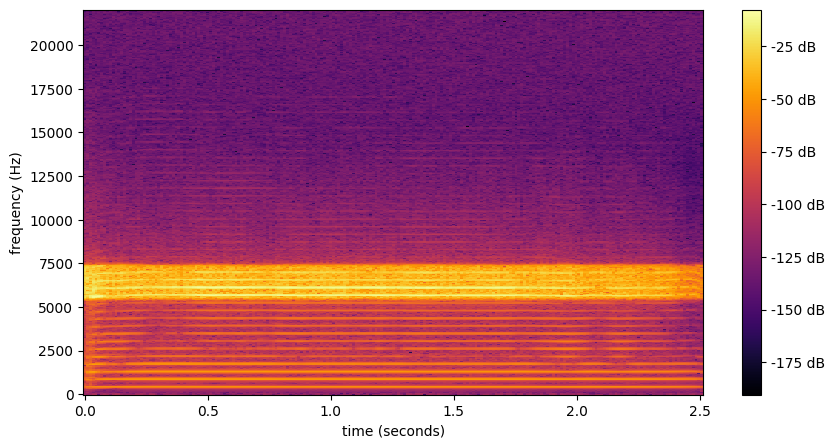

In [10]:
## APPLYING THE BPF CREATED TO THE SOUND TRUMPET

#Step 01: Reading the sound TRUMPET
sound_array, sampling_rate = read_sound('../sounds/487465-trumpet.wav')

# Step 02: Filtering the sound TRUMPET by convolving it with the IR of the filter
filtered_sound = signal.lfilter(hk, 1, sound_array)

# Step 03: Displaying the audio and spectogram of the filtered sound

ipd.display(ipd.Audio(data=filtered_sound, rate=sampling_rate))
print(f"Spectogram of filtered sound TRUMPET with BPF of index {k}")
display_spectrogram(filtered_sound, 512, 1024, sampling_rate)

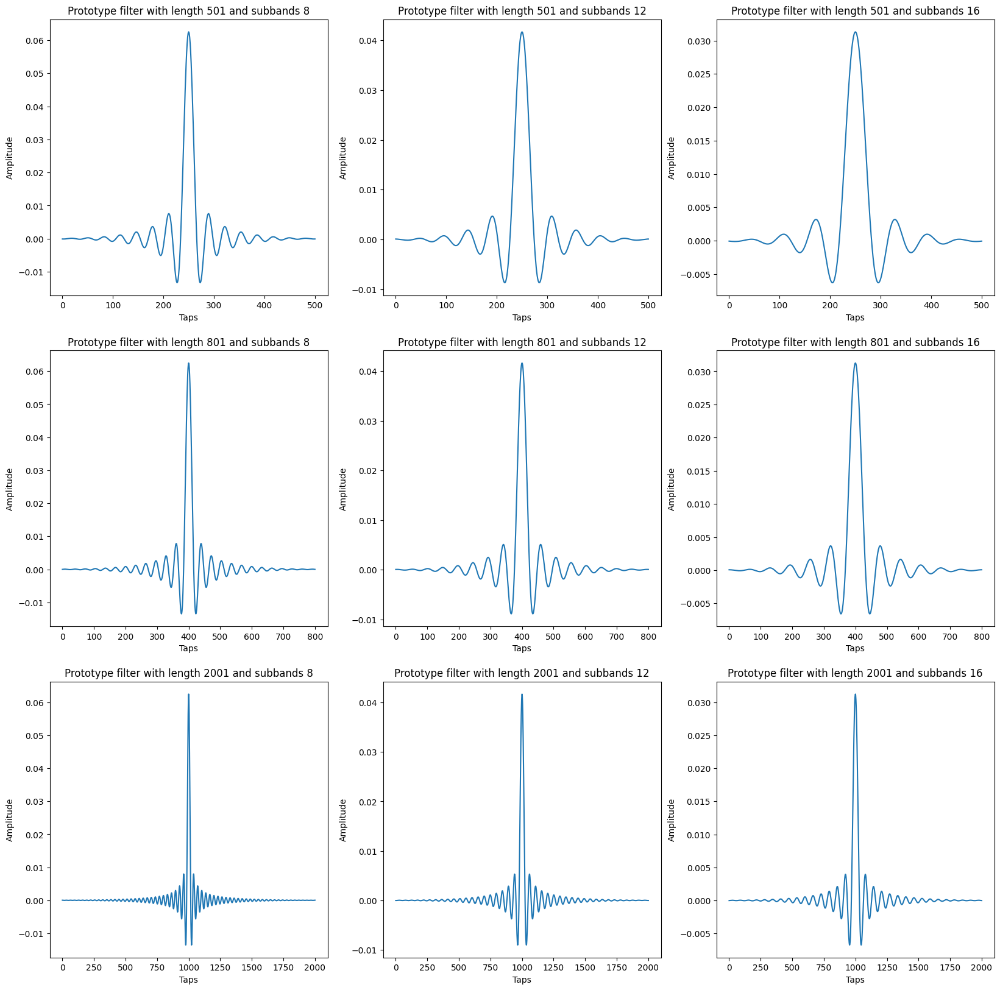

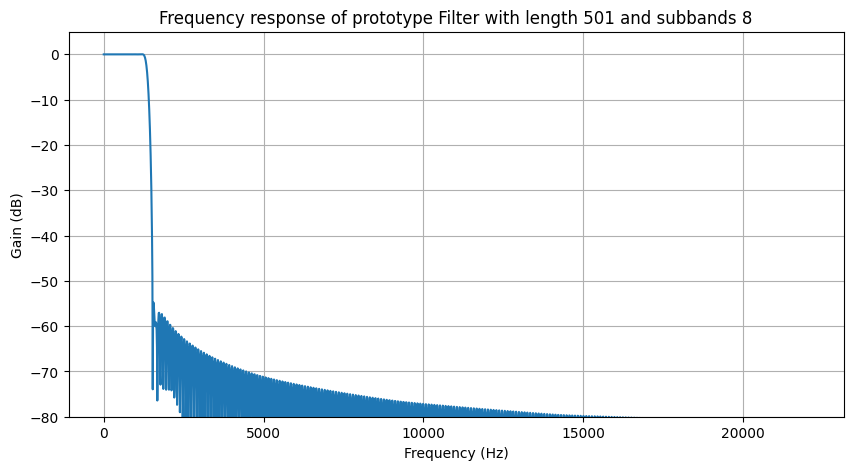

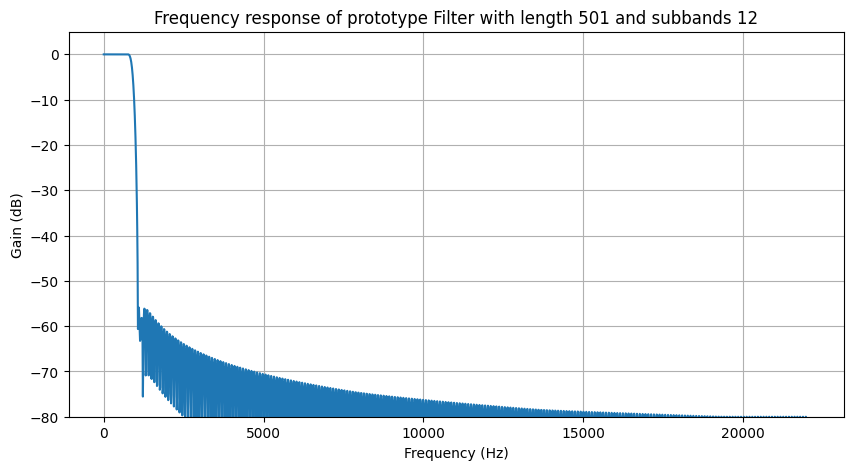

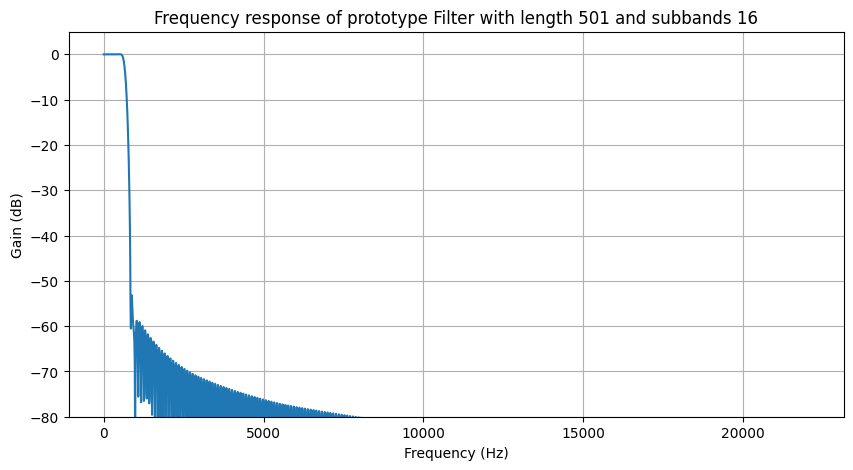

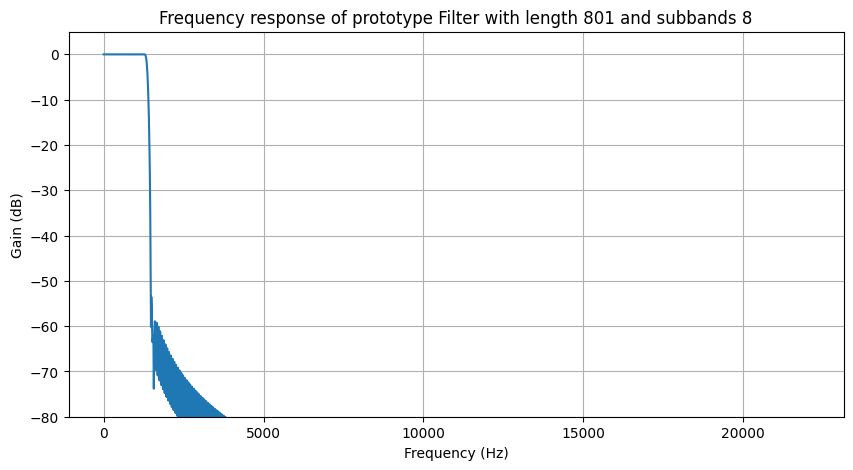

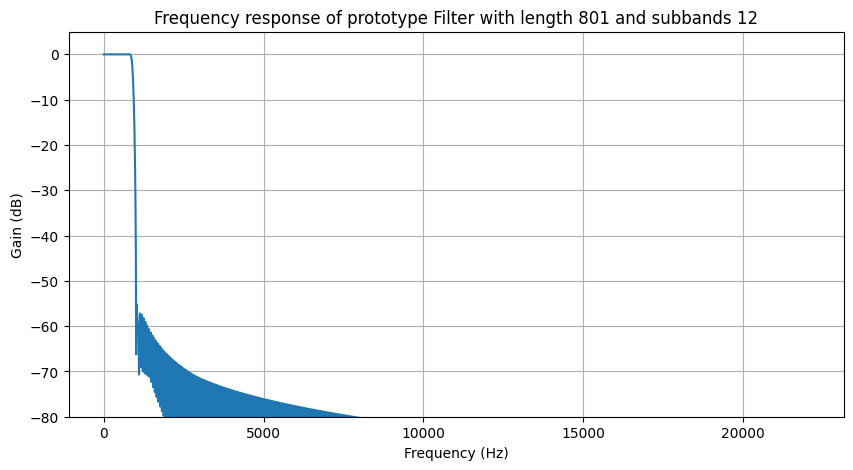

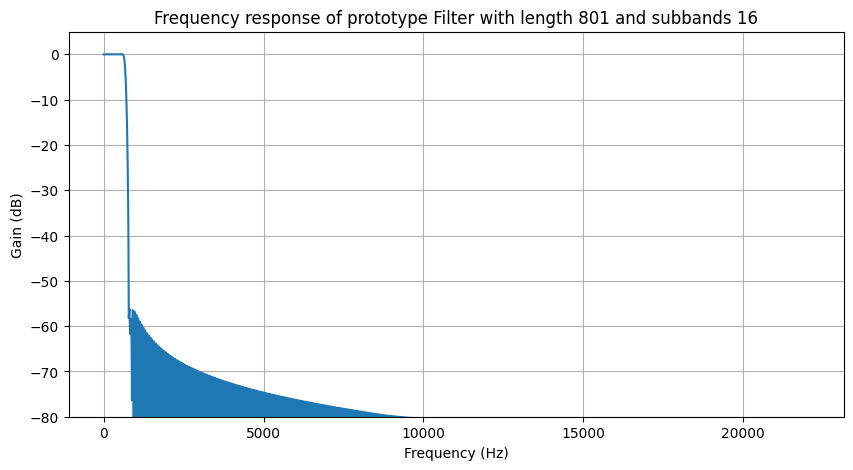

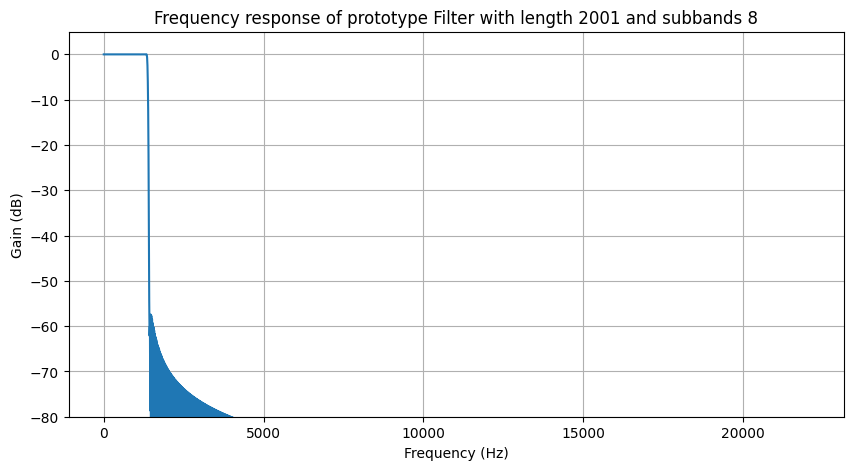

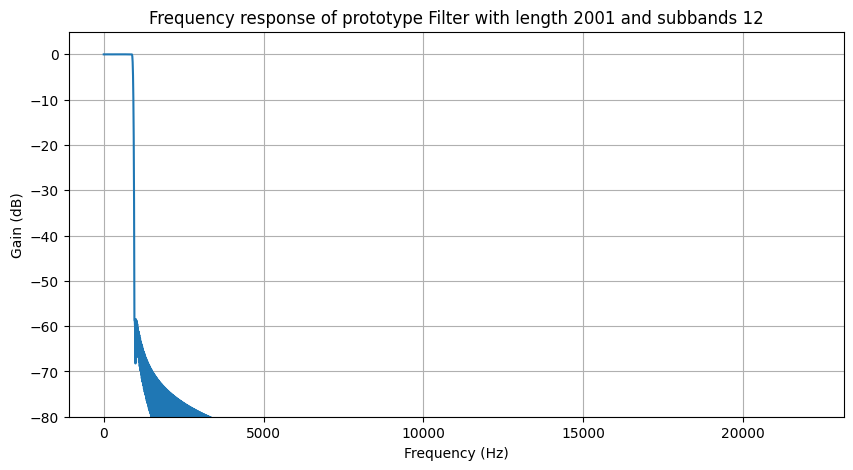

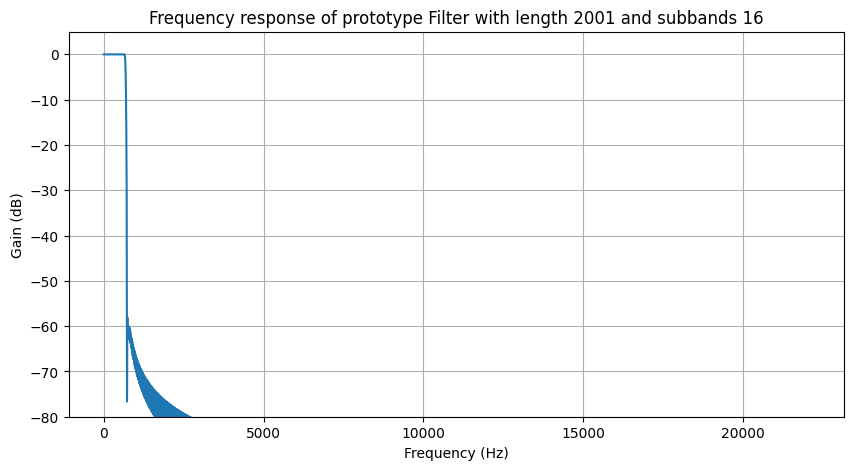

<Figure size 1000x500 with 0 Axes>

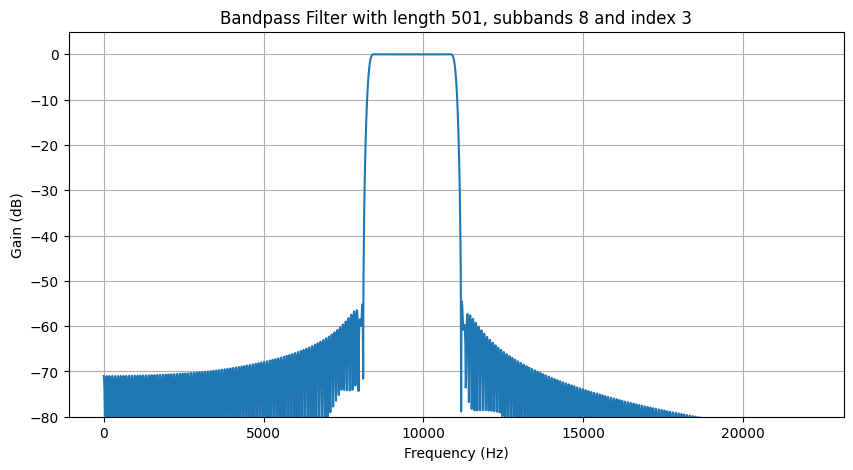

<Figure size 1000x500 with 0 Axes>

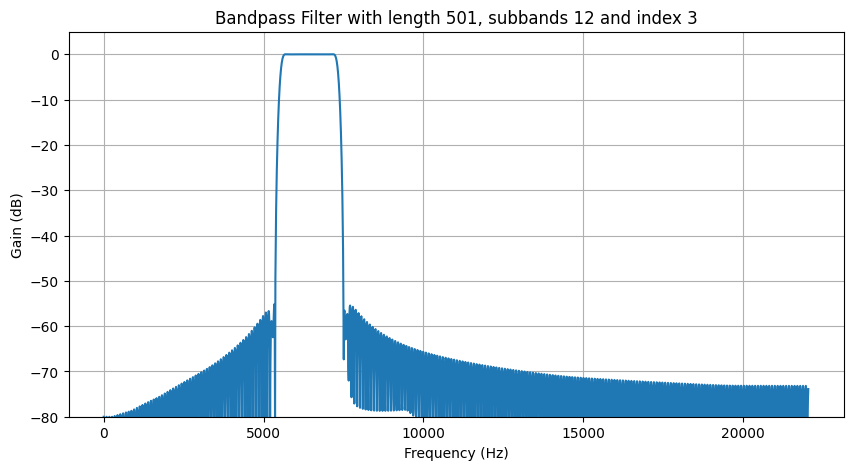

<Figure size 1000x500 with 0 Axes>

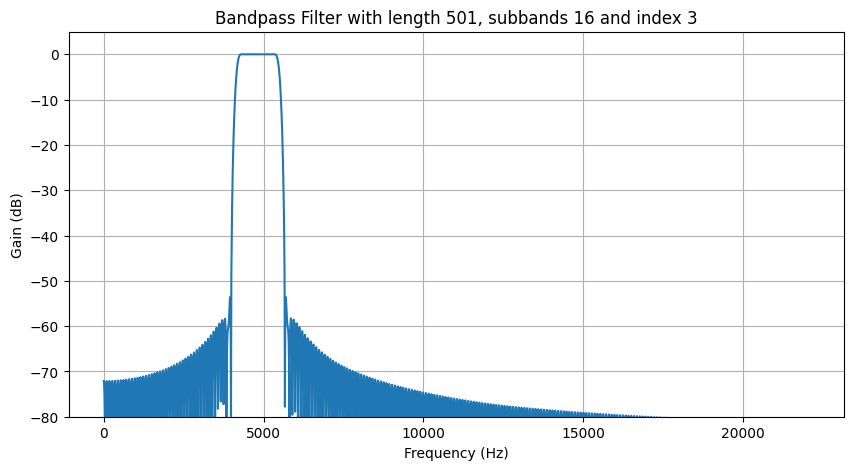

<Figure size 1000x500 with 0 Axes>

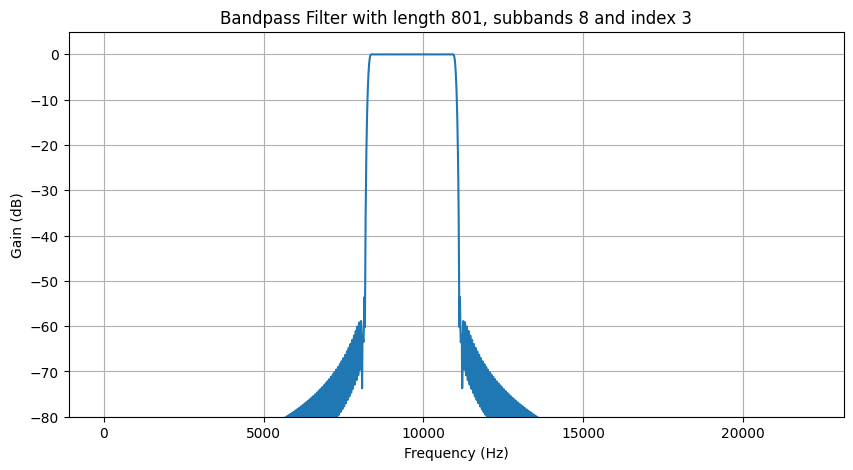

<Figure size 1000x500 with 0 Axes>

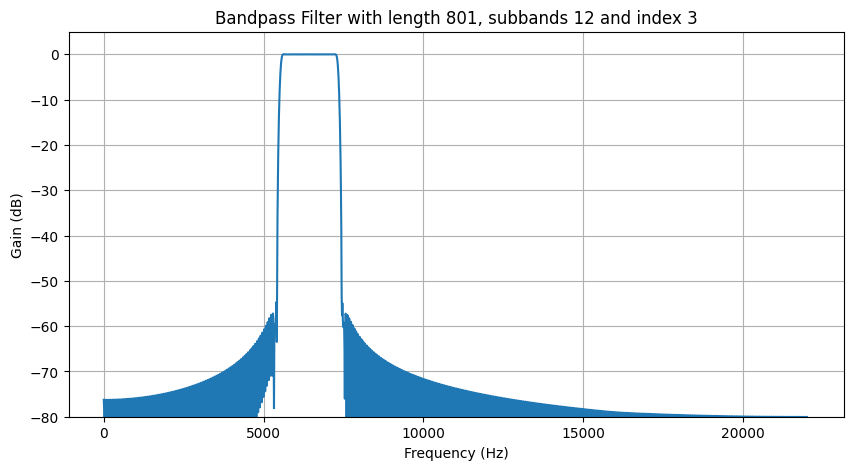

<Figure size 1000x500 with 0 Axes>

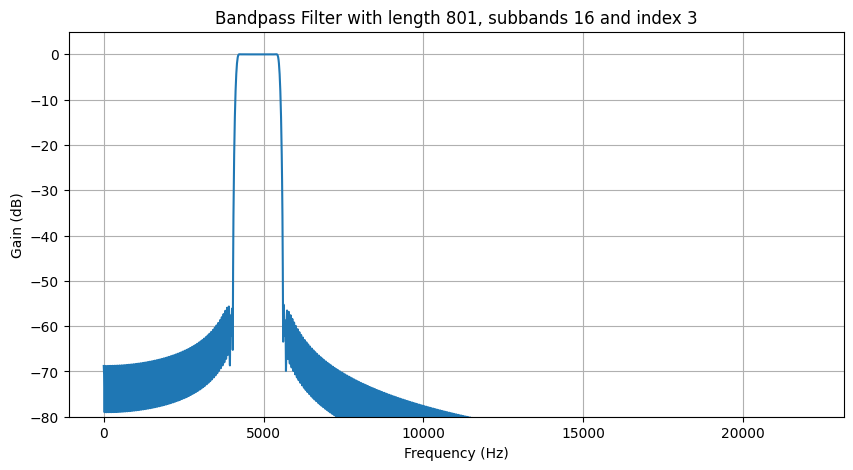

<Figure size 1000x500 with 0 Axes>

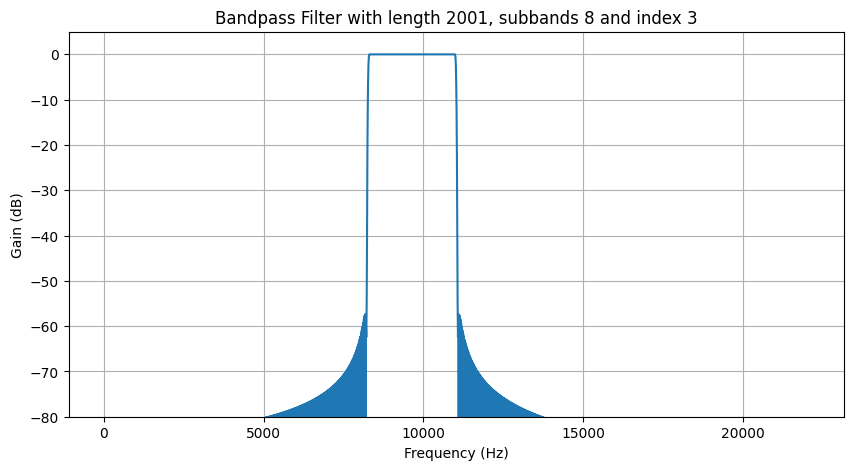

<Figure size 1000x500 with 0 Axes>

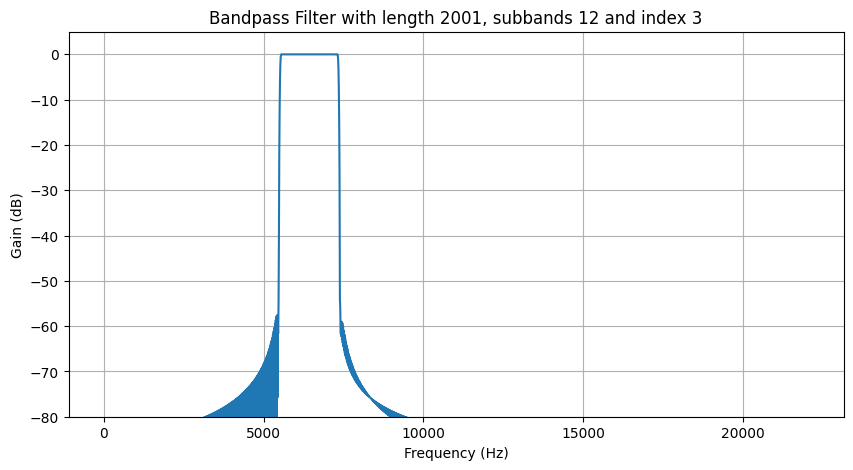

<Figure size 1000x500 with 0 Axes>

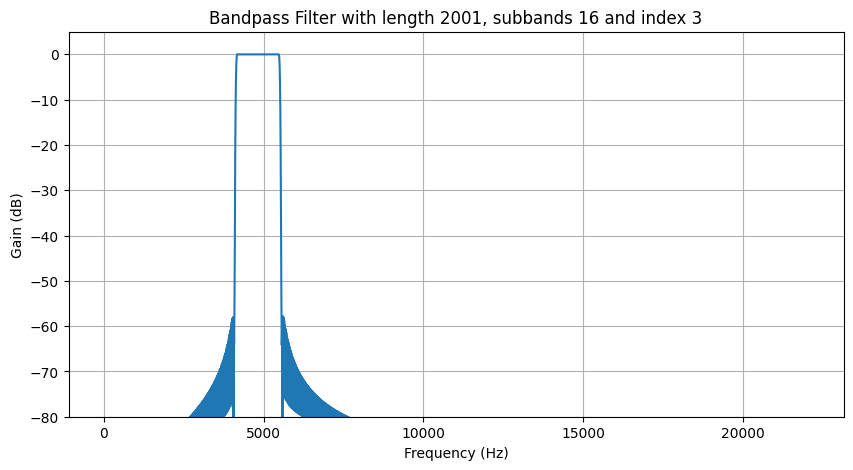

Trumpet sound with BPF of length 501, subband 8 and index 3


Spectogram of complete filtered Trumpet sound with BPF of length 501, subband 8 and index 3


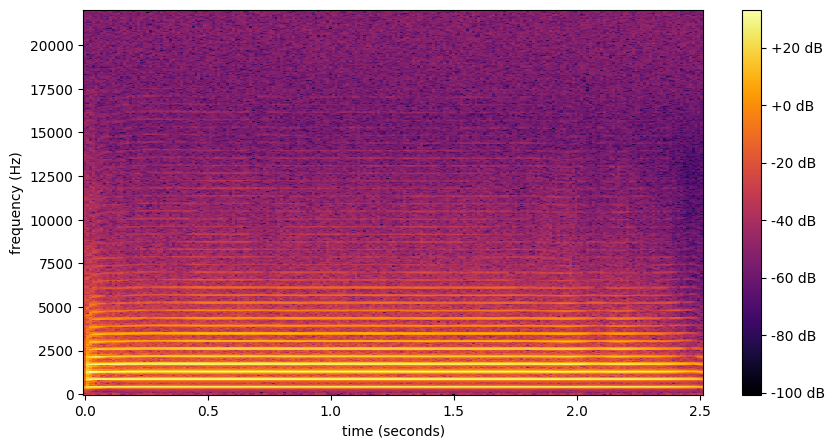

Trumpet sound with BPF of length 501, subband 12 and index 3


Spectogram of complete filtered Trumpet sound with BPF of length 501, subband 12 and index 3


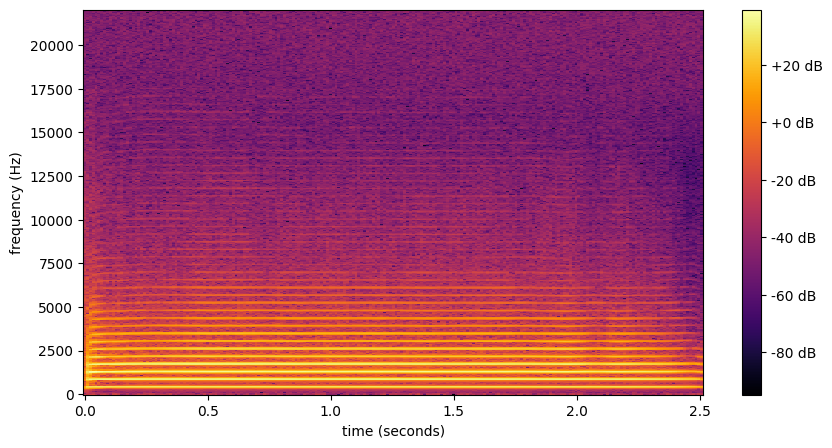

Trumpet sound with BPF of length 501, subband 16 and index 3


Spectogram of complete filtered Trumpet sound with BPF of length 501, subband 16 and index 3


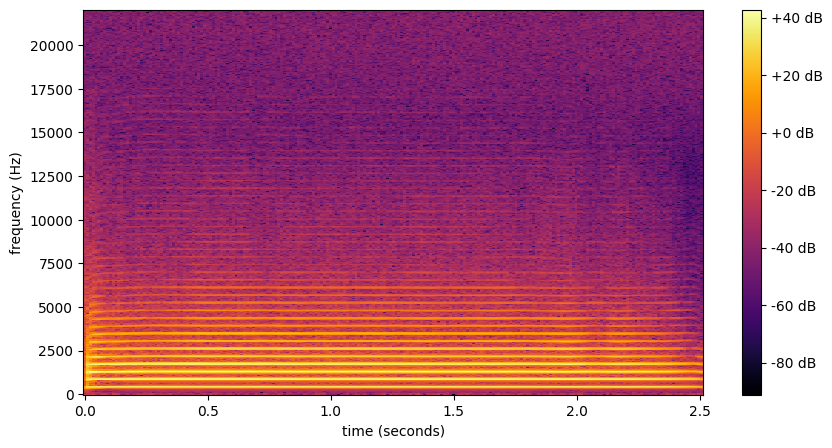

Trumpet sound with BPF of length 801, subband 8 and index 3


Spectogram of complete filtered Trumpet sound with BPF of length 801, subband 8 and index 3


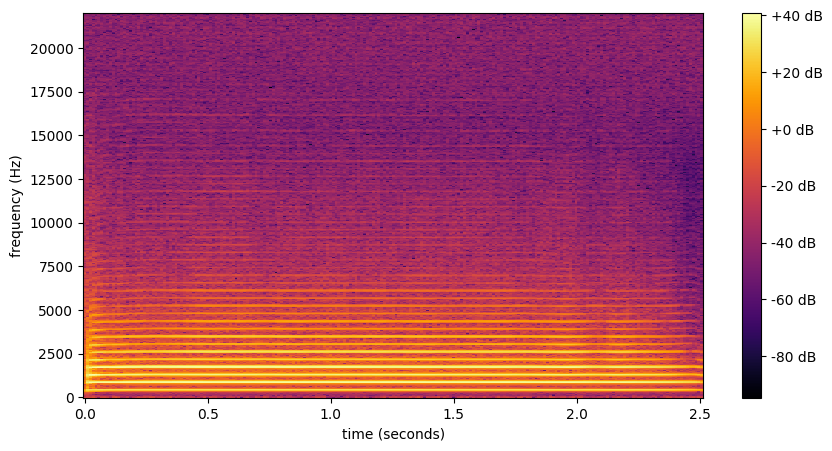

Trumpet sound with BPF of length 801, subband 12 and index 3


Spectogram of complete filtered Trumpet sound with BPF of length 801, subband 12 and index 3


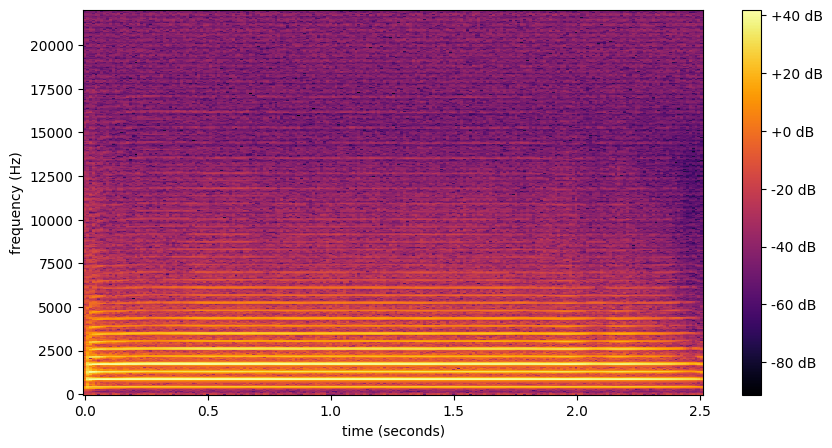

Trumpet sound with BPF of length 801, subband 16 and index 3


Spectogram of complete filtered Trumpet sound with BPF of length 801, subband 16 and index 3


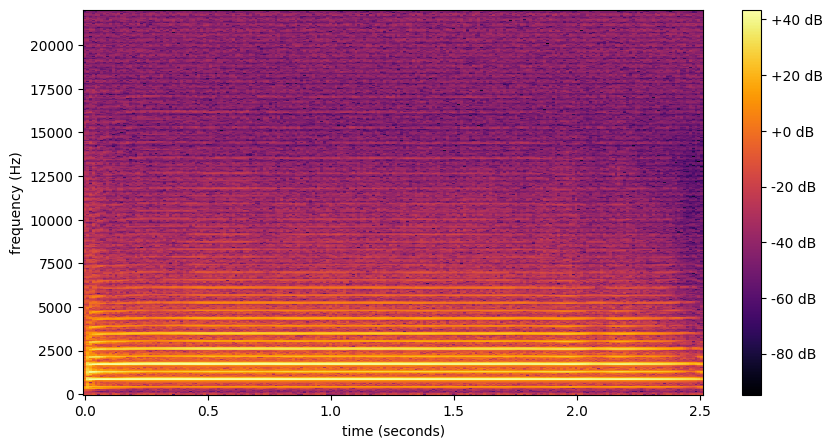

Trumpet sound with BPF of length 2001, subband 8 and index 3


Spectogram of complete filtered Trumpet sound with BPF of length 2001, subband 8 and index 3


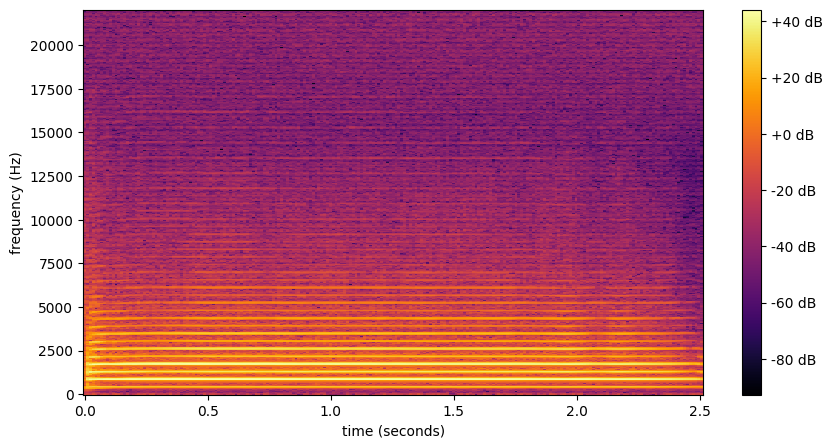

Trumpet sound with BPF of length 2001, subband 12 and index 3


Spectogram of complete filtered Trumpet sound with BPF of length 2001, subband 12 and index 3


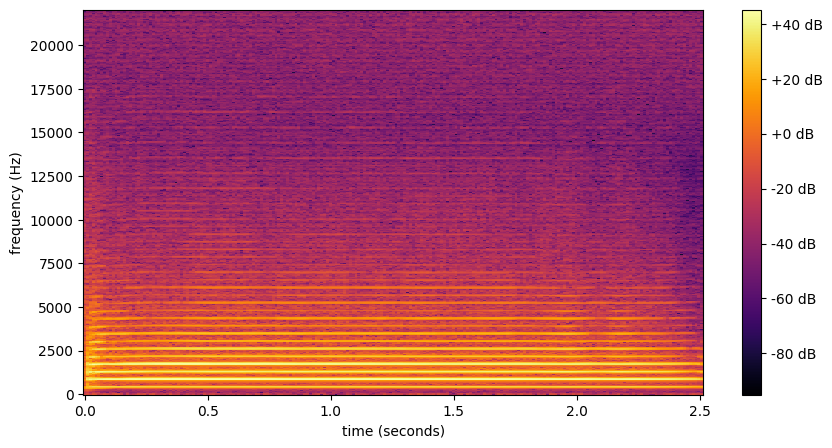

Trumpet sound with BPF of length 2001, subband 16 and index 3


Spectogram of complete filtered Trumpet sound with BPF of length 2001, subband 16 and index 3


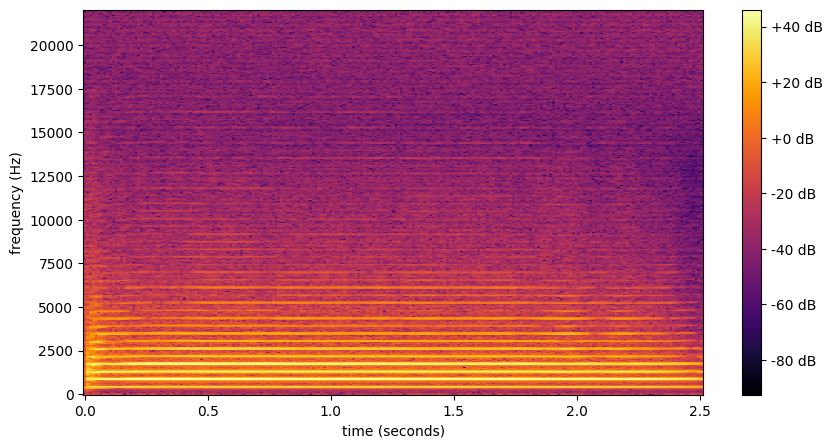

In [11]:
## IMPLEMENTING DIFFERENT COMPLETE FILTER BANKS AND APPLYING THEM TO THE SOUND TRUMPET

# Step 01: Defining the Parameters for the filter bank
N_values = [501, 801, 2001]
L_values = [8,12,16]  
fs = 44100  
h_all = []
# Step 02: Generating  the prototype filter(s)
for N in N_values:
  for L in L_values:

    h = prototype_filter(N, L)
    h_all.append(h)
    

# Step 03: Ploting the prototype filter(s)
fig, ax = plt.subplots(3,3,figsize=(20, 20))

ax[0,0].plot(h_all[0])
ax[0,0].set_xlabel('Taps')
ax[0,0].set_ylabel('Amplitude')
ax[0,0].set_title(f"Prototype filter with length {N_values[0]} and subbands {L_values[0]}")

ax[0,1].plot(h_all[1])
ax[0,1].set_xlabel('Taps')
ax[0,1].set_ylabel('Amplitude')
ax[0,1].set_title(f"Prototype filter with length {N_values[0]} and subbands {L_values[1]}")

ax[0,2].plot(h_all[2])
ax[0,2].set_xlabel('Taps')
ax[0,2].set_ylabel('Amplitude')
ax[0,2].set_title(f"Prototype filter with length {N_values[0]} and subbands {L_values[2]}")

ax[1,0].plot(h_all[3])
ax[1,0].set_xlabel('Taps')
ax[1,0].set_ylabel('Amplitude')
ax[1,0].set_title(f"Prototype filter with length {N_values[1]} and subbands {L_values[0]}")

ax[1,1].plot(h_all[4])
ax[1,1].set_xlabel('Taps')
ax[1,1].set_ylabel('Amplitude')
ax[1,1].set_title(f"Prototype filter with length {N_values[1]} and subbands {L_values[1]}")

ax[1,2].plot(h_all[5])
ax[1,2].set_xlabel('Taps')
ax[1,2].set_ylabel('Amplitude')
ax[1,2].set_title(f"Prototype filter with length {N_values[1]} and subbands {L_values[2]}")

ax[2,0].plot(h_all[6])
ax[2,0].set_xlabel('Taps')
ax[2,0].set_ylabel('Amplitude')
ax[2,0].set_title(f"Prototype filter with length {N_values[2]} and subbands {L_values[0]}")

ax[2,1].plot(h_all[7])
ax[2,1].set_xlabel('Taps')
ax[2,1].set_ylabel('Amplitude')
ax[2,1].set_title(f"Prototype filter with length {N_values[2]} and subbands {L_values[1]}")

ax[2,2].plot(h_all[8])
ax[2,2].set_xlabel('Taps')
ax[2,2].set_ylabel('Amplitude')
ax[2,2].set_title(f"Prototype filter with length {N_values[2]} and subbands {L_values[2]}")

plt.show()

# Step 04: Plotting the frequency response of the prototype filter
w_all = []
H_all = []

for h in h_all:
    w, H = signal.freqz(h, [1], worN=2000, fs=fs)
    w_all.append(w)
    H_all.append(H)

plot_freq_response(w_all[0], H_all[0], f"Frequency response of prototype Filter with length {N_values[0]} and subbands {L_values[0]}")
plot_freq_response(w_all[1], H_all[1], f"Frequency response of prototype Filter with length {N_values[0]} and subbands {L_values[1]}")
plot_freq_response(w_all[2], H_all[2], f"Frequency response of prototype Filter with length {N_values[0]} and subbands {L_values[2]}")

plot_freq_response(w_all[3], H_all[3], f"Frequency response of prototype Filter with length {N_values[1]} and subbands {L_values[0]}")
plot_freq_response(w_all[4], H_all[4], f"Frequency response of prototype Filter with length {N_values[1]} and subbands {L_values[1]}")
plot_freq_response(w_all[5], H_all[5], f"Frequency response of prototype Filter with length {N_values[1]} and subbands {L_values[2]}")

plot_freq_response(w_all[6], H_all[6], f"Frequency response of prototype Filter with length {N_values[2]} and subbands {L_values[0]}")
plot_freq_response(w_all[7], H_all[7], f"Frequency response of prototype Filter with length {N_values[2]} and subbands {L_values[1]}")
plot_freq_response(w_all[8], H_all[8], f"Frequency response of prototype Filter with length {N_values[2]} and subbands {L_values[2]}")
plt.show()


# Step 05: Creating the bandpass filter
k = 3 
N_vals = [501, 501, 501, 801, 801, 801, 2001, 2001, 2001]
L_vals = [8, 12, 16, 8, 12, 16, 8, 12, 16]
for h,N,L in zip(h_all, N_vals,L_vals):
  hk = modulate_filter(h, L, k)
  # Step 06: Plotting the frequency response of the bandpass filter
  plt.figure(figsize=(10, 5))
  w, H = signal.freqz(hk, [1], worN=2000, fs=fs)
  plot_freq_response(w, H, f"Bandpass Filter with length {N}, subbands {L} and index {k}")
  plt.show()

# Step 07: Initializing an empty array with the same length as the original sound
y = np.zeros(len(sound_array))

# Step 08: Applying the whole filter bank to the sound Trumpet
for h, N, L in zip(h_all, N_vals, L_vals):
  for k in range(L):
    # Step 08.1: Modulating the filter
    hk = modulate_filter(h, L, k)
    # Step 08.2: Filtering the sound for the given index
    filtered_sound = signal.lfilter(hk, 1, sound_array)
    # Step 08.3: Adding the filtered sound of index k to the resulting array/sound
    y += filtered_sound

  # Step 09: Displaying the audio and the spectogram of sound Trumpet
  print(f"Trumpet sound with BPF of length {N}, subband {L} and index 3")
  ipd.display(ipd.Audio(data=y, rate=sampling_rate))
  print(f"Spectogram of complete filtered Trumpet sound with BPF of length {N}, subband {L} and index 3")
  display_spectrogram(y, 512, 1024, sampling_rate)

**Questions**
1. Implement a low-pass filter and convert it to a band-pass filter. Explain how it works. Implement one bandpass filter (define your own variables) and explain the result obtained when applying it to a particular sound (use one of the sounds in the sound directory).

    <font color=red> I have decided to use the sound TRUMPET.
    The functionality of this exercise/code is the following.
    - I define the parameters of the prototype filter: N and L, which is the length of the filter and the number of subbands. The prototype filter is a Low Pass filter that has these 2 characteristics. In my case N = 801 because I saw on part 1 that it was a good enough LPF, and the subbands, that is, into how many equal-spaced bands the filter will be divided, is 12. In this case I chose a random number similar to the one provided on the code (8).
    With this prototype, the length of the filter, and the index of the band pass filter, I create the Band Pass filter. This band-pass filter is created by a cosine modulation of the lowpass prototype filter, which can realize parallel M-channel filter banks (in my case, 12) with nearly perfect reconstruction. In addition, the cutoff frequency (normalized) is given by pi/2·M, which in my case is pi/2·12, and without normalizing it results in 918.75 Hz, which is what the frequency response of the prototype filter looks like.
    And when the bandpass filter is created, this frequency is taken into account when creating the range of frequencies that will be mantained, in this case, around 5500 Hz to 7500 Hz, whereas the rest are minimized or even decreased.
    
    When I apply this given filter into the white noise sound, now I only hear the middle range of frequencies, that is, the range of frequencies that have been mantained by the bandpass filter. This filter is pretty sharp, meaning that even the neighbouring frequencies to the extremes of the ones mantained have been decreased in magnitude enough such that they are not hearable anymore. 
    
    We can check this with the spectogram, where we can see that only the frequencies from 5500 Hz to 7500 Hz are the ones with the same magnitude as the original sound, and although a bit below 5000 Hz and a bit above 7500 Hz we see that they have more magnitude than the other ones, we can still see on the legend that they are between -60 and -80 dBs less than the original. </font>


2. Implement a complete filter bank. Apply it to the sound chosen. Change the size of the filter, N, and the number of bands, L. What is the bandwith in Hz of each band-pass filter as a function of L? Is the output sound identical independent of the values of L and N, why?, support the answer plotting the sum of the magnitude of the frequency responses of all the band pass filters for different values. 

    <font color=red> The sound I chose previously was the Trumpet signal. I think it is a very easy signal to see when the filter works and when it doesn't, since it contains all frequencies throughout the spectrum at the same magnitude. 
    
    I have decided to use 3 different values for the length of the filter, and other 3 different values for the subbands of the filter. This way we will have 9 different prototype filters with 9 different frequency responses. So we will also have 9 different band pass filters that will be applied to the sound using the complete filter bank method. Meaning that we will have 9 different filtered sounds with their respective spectograms. 
    
    - The lengths of the filters are: 501, 801 and 2001. 
    
    - The subbands of the filters are 8, 12, and 16.

    We will start by analyzing the difference on the prototype filters plots:
    - The greater the length of the filter, the more samples it has, therefore, the narrower the repetitions/patterns are. 
    - The greater the subbands of the filter, the less amplitude the prototype filter has. We can see how it starts with an amplitude peak of 0.6 with 8 subbands, and ends up with 0.030 with 16 subbands, which is 20 times smaller.

    Now we can move on to analyzing the difference on the frequency response of the prototype filters.
    - The greater the subbands, the smaller the lowpass filter is, that is, the less frequencies it mantains and the more it dampens until them being unperceivable. With 8 subbands the cutoff frequency is around 1378 Hz, with 12 subbands is 918 Hz, and with 16 is around 690 Hz.
    - With the filter length we cannot see a very big difference between the frequency responses, but we know that the filter length affects the sharpness of the filter. It is not extremely noticeable, but we can see how at the cutoff frequency, the larger the filter length the straighter the line decaying in amplitude is. In addition, the replies or the artifacts are also reduced when the filter length is increased. 

    Let us move on to the bandpass frequency responses.
    - On the bandpass filters we can see the same phenomenons occurr, but "duplicated". 
    - The greater the subbands, the narrower the bandpass filter is.
    - The greater the filter length, the sharper the bandpass is.
    - In addition, we can see that the greater the subband, the lower the bandpass is located. This makes sense, since on the frequency response of the lowpass filter we saw how the greater the subband the lower the cutoff frequency was. 
    In these frequency responses we can see how the 8 subband is centered around 9000 Hz, the 12 subband centered around 6500 Hz, and the 16 subband centered around 4600-4800 Hz.   

    Now, the only thing left to compare is the resulting filtered audios and their respective spectograms.
    - If we have chosen the correct parameters we will be able to hear no difference in comparison to the original sound. 
    This occurs when the filter length is 501, there is no change in pitch. I cannot quite perceive the difference between filter length 501 with subbands 8, 12 and 16, but according to the legend of the spectograms, there was a slight increase in magnitude over all the frequencies of the spectrum. 
    - When listening to the resulting audios with the filter length 801, I can perceive some frequency changes. The one with 8 subbands is the most similar to the previous ones, but the one with 12 subbands has lost some low frequencies, and the one with 16, even more. This lasst one sounds completely out of tune. We can check this by looking at the spectogram, where we see that the fundamental frequency fades in both spectograms, and this fade is more noticeable on the 16 subbands spectogram, resulting in this out of tune sound.
    - Lastly, for the filter length 2000, the lower frequencies have been slightly "recovered" but it still sounds higher pitched than the original sound. When looking at the spectogram we can see that the greater the subband the better the lower frequencies have been recovered, and that is why out of these 3 audios, the one that sounds better it is the last one, wit subband 16.

    Overall, I find it very hard to take conclusions out of this exercise. But I will say that in order to correctly reconstruct a signal we need to be very accurate with both the length of the filter and the subbands used. If we define one correctly but not the other, we will not have a correct resulting signal. That is why on this exercise, when using filter length 801 the sound worsened as we increased the subbands, but when using filter length 2001 it was better as we increased them. </font>
---

## Part 3 - Critical sampling
Experiment with critical sampling (the bandpass signals ocupy the same memory than the original signal), choosing the value L as the number of subbands, then downsampling each filtered band by L and finally upsampling them by L at the reconstruction stage.

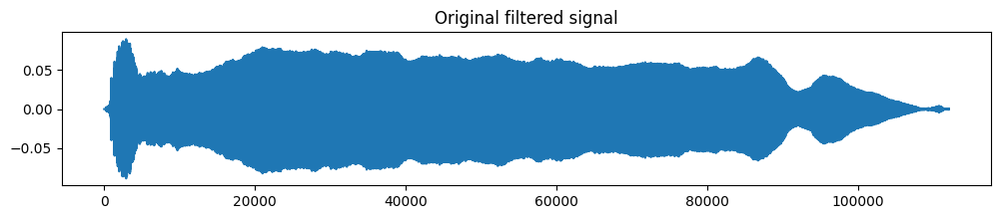

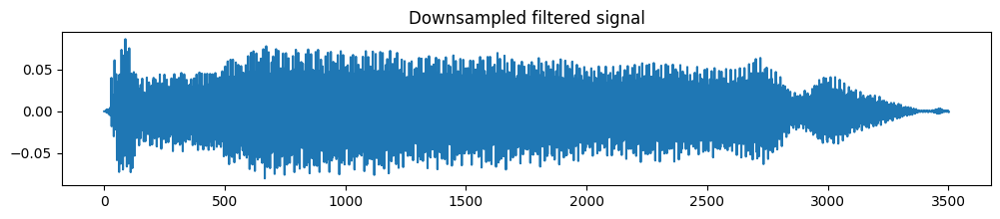

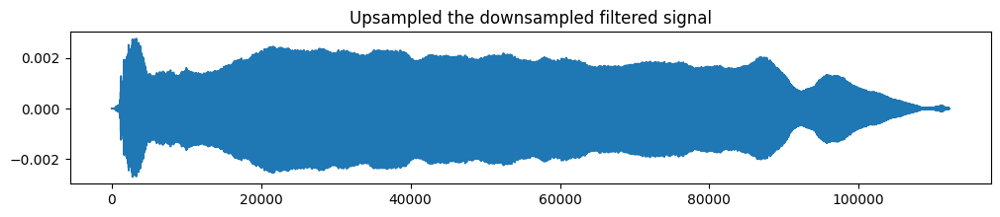

In [12]:
# downsample and upsample a filtered signal

# Parameters for the filter bank
N = 512  # Length of the prototype filter
L = 32   # Number of subbands
fs = 44100  # Sampling rate

# Generate the prototype filter
h = prototype_filter(N, L)

# generate bandpass filter
k = 3
hk = modulate_filter(h, L, k)

# filter a sound with the bandpass filter
sound_array, sampling_rate = read_sound('../sounds/487465-trumpet.wav')

# Filter the signal
y = signal.lfilter(hk, 1.0, sound_array)
# down-sample the filtered signal
yd = y[::L]

# Upsample
yu = np.zeros(len(yd) * L)
yu[::L] = yd
# Filter with same filter than in encoding
yu = signal.lfilter(hk, 1.0, yu)

# Plot the original and reconstructed signals
plt.figure(figsize=(12, 2))
plt.plot(y)
plt.title("Original filtered signal")
plt.show()
ipd.display(ipd.Audio(data=y, rate=sampling_rate))

plt.figure(figsize=(12, 2))
plt.plot(yd)
plt.title("Downsampled filtered signal")
plt.show()
ipd.display(ipd.Audio(data=yd, rate=sampling_rate/L))

plt.figure(figsize=(12, 2))
plt.plot(yu)
plt.title("Upsampled the downsampled filtered signal")
plt.show()
ipd.display(ipd.Audio(data=yu, rate=sampling_rate))


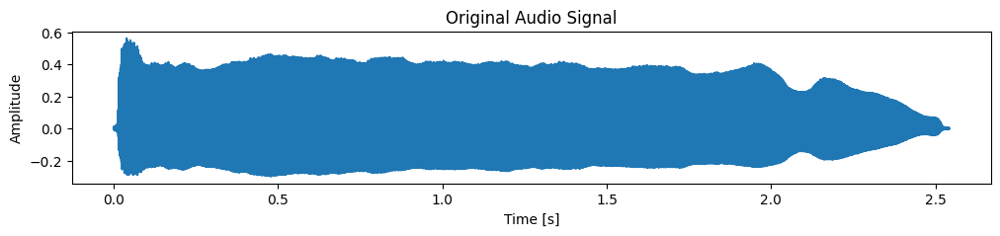

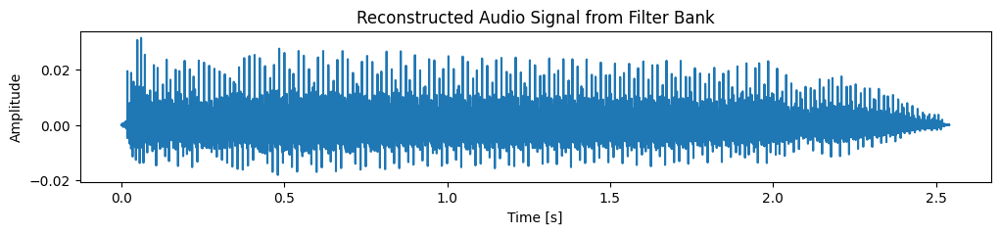

In [13]:
# encode and decode a signal with an bank of filters

# Parameters for the filter bank
N = 128  # Length of the prototype filter
L = 64   # Number of subbands
fs = 44100  # Sampling rate

sound_array, sampling_rate = read_sound('../sounds/487465-trumpet.wav')
t = np.linspace(0, len(sound_array)/sampling_rate, len(sound_array), endpoint=False)

# Analysis (encoding): split the signal into subbands
subbands = analysis_filter_bank(sound_array, L, N)

# Synthesis (decoding): reconstruct the signal from subbands
reconstructed_signal = synthesis_filter_bank(subbands, L, N)

# Plot the original and reconstructed signals
plt.figure(figsize=(12, 2))
plt.plot(t, sound_array)
plt.title("Original Audio Signal")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.show()
ipd.display(ipd.Audio(data=sound_array, rate=sampling_rate))

plt.figure(figsize=(12, 2))
plt.plot(t[:len(reconstructed_signal)],reconstructed_signal)
plt.title("Reconstructed Audio Signal from Filter Bank")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.show()
ipd.display(ipd.Audio(data=reconstructed_signal, rate=sampling_rate))



<font color=red> ***MY MODIFIED CODE*** </font>

64
64
64
64


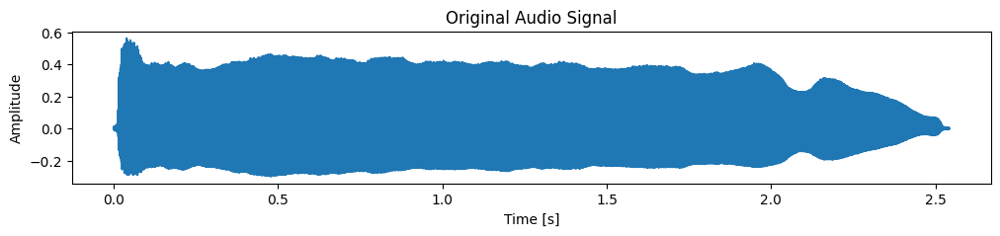

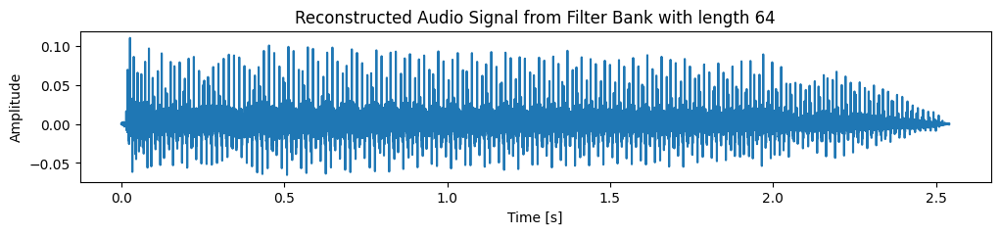

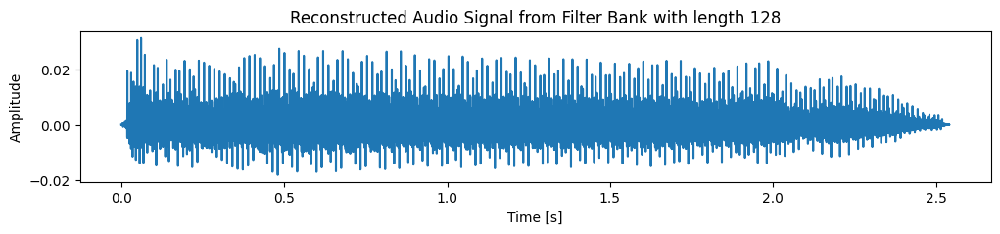

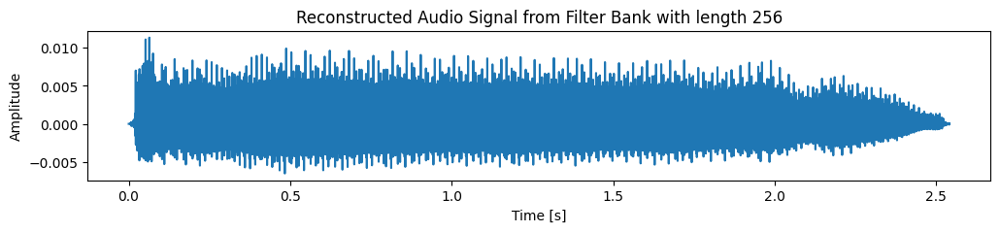

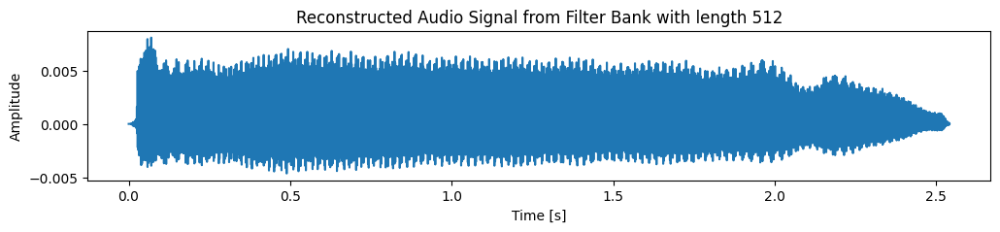

In [14]:
## CREATING A FILTER BANK FOR L NUMBER OF SUBBANDS AND APPLYING THEM TO THE SOUND TRUMPET

# Step 01: Defining the parameters of the filter
N_vals = [64, 128, 256, 512]
L = 64
fs = 44100

# Step 02: reading the Trumpet sound
sound_array, sampling_rate = read_sound('../sounds/487465-trumpet.wav')
t = np.linspace(0, len(sound_array)/sampling_rate, len(sound_array), endpoint=False)

# Step 03: Analysis (encoding)-> spliting the signal into subbands
subbands_all = []
for N in N_vals:
    subbands = analysis_filter_bank(sound_array, L, N)
    print(len(subbands))
    subbands_all.append(subbands)

# Step 04: Synthesis (decoding)-> reconstructing the signal from subbands
reconstructed_signal1 = synthesis_filter_bank(subbands_all[0], L, N_vals[0])
reconstructed_signal2 = synthesis_filter_bank(subbands_all[1], L, N_vals[1])
reconstructed_signal3 = synthesis_filter_bank(subbands_all[2], L, N_vals[2])
reconstructed_signal4 = synthesis_filter_bank(subbands_all[3], L, N_vals[3])

# Plot the original and reconstructed signals
plt.figure(figsize=(12, 2))
plt.plot(t, sound_array)
plt.title("Original Audio Signal")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.show()
ipd.display(ipd.Audio(data=sound_array, rate=sampling_rate))

plt.figure(figsize=(12, 2))
plt.plot(t[:len(reconstructed_signal1)],reconstructed_signal1)
plt.title("Reconstructed Audio Signal from Filter Bank with length 64")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.show()
ipd.display(ipd.Audio(data=reconstructed_signal1, rate=sampling_rate))

plt.figure(figsize=(12, 2))
plt.plot(t[:len(reconstructed_signal2)],reconstructed_signal2)
plt.title("Reconstructed Audio Signal from Filter Bank with length 128")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.show()
ipd.display(ipd.Audio(data=reconstructed_signal2, rate=sampling_rate))

plt.figure(figsize=(12, 2))
plt.plot(t[:len(reconstructed_signal3)],reconstructed_signal3)
plt.title("Reconstructed Audio Signal from Filter Bank with length 256")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.show()
ipd.display(ipd.Audio(data=reconstructed_signal3, rate=sampling_rate))

plt.figure(figsize=(12, 2))
plt.plot(t[:len(reconstructed_signal4)],reconstructed_signal4)
plt.title("Reconstructed Audio Signal from Filter Bank with length 512")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.show()
ipd.display(ipd.Audio(data=reconstructed_signal4, rate=sampling_rate))

In [15]:
## CHECKING CRITICAL SAMPLING
#size of all subbands (encoded matrix array) == size of input signal
size_input_signal = len(sound_array)
size_all_subbands1 = np.size(subbands_all[0])
size_all_subbands2 = np.size(subbands_all[1])
size_all_subbands3 = np.size(subbands_all[2])
size_all_subbands4 = np.size(subbands_all[3])

print("Size of input signal:", size_input_signal)
print("Size encoded subband with length 64:", size_all_subbands1)
print("Size encoded subband with length 128:", size_all_subbands2)
print("Size encoded subband with length 256:", size_all_subbands3)
print("Size encoded subband with length 512:", size_all_subbands4)

Size of input signal: 112076
Size encoded subband with length 64: 112064
Size encoded subband with length 128: 112064
Size encoded subband with length 256: 112064
Size encoded subband with length 512: 112064


**Questions:**

1. Create a filter bank for L number of subbands. Apply it to a sound from the sounds directory while downsampling by L the subbands (encoded signal), then upsampling the subbands and addindg them together (decoded signal). Try to get the best reconstruction by trying different filter lengths (ex: 64, 128, 256). Explain the result.

    <font color=red> I have applied it again to the trumpet sound. I mantained the number of subbands L to 64, and I tried to reconstruct the signal by using 4 different filter with lengths 54, 128, 256 and 512, since I was not very satisfied with the result of the reconstructed signal wit the 256 filter and I wanted to see whether doubling the length again would have any kind of positive impact over the reconstruction.
    I have seen that the greater the filter length, the more constant or smooth the sound is. We can hear how with the filter lengths 64 and 128, the reconstructed signal has a lot of "silences", which makes the sound very rough and annoying, as if there was a lot of information missing. In fact, there is information missing, since the smaller the filter length, the less samples it gets, so the worse the reconstructed signal will sound. However, it arrives to a point where the perceived difference is minimal and there is no need for making the computation more costly. This would be the case for the filter length of 512, it does sound different than the filtered with 256, but it is not equal to the original one.
    In addition, we also know that the less subbands that we have, the better, if we were to reduce the subbands by half, the 256 filtered signal would be much better than it is. This would be due to the fact that the bandpass filters in the filter bank would have a greater range of frequencies mantained, since we saw on the previous exercise that the more subbands we had, the narrower the bandpass filter was.</font>

2. Prove that the encoding process performs critical sampling, so the size of all the subbands (the encoded matrix array) is equal to the size of the input signal. Add the needed code.

    <font color=red> I have created a new cell where I find the length of the original signal, and then the length of the subbands signals that I get for every filter length. All of them should be equal to the length of the original signal, which is 112076. I compute the size of the subbands by using np.size(), since if i use only len() I am computing only the size of 1 dimension (64).
    
    However, I do not get exactly the same result, for all subbands I get 112064. This is not an error, it is actually correct, and it is given by how the alaysis_filter_bank function is defined.
    

    We have the line "subband_length = len(x) // M", where len(x) is equal to len(sound_array) and is equal to 112076, and M is equal to L so it is equal to 64. The problem is that 112076 / 64 does not result in an integer number (1751.18), so the subband length is rounded to the closest number (1751). So then, when we search for the subband length, we do 1751 * 64, which results in 112064.
    </font>

---